# YOLOv4 on D-Fire: held-out evaluation, comparison with YOLOv5s and speed benchmark

This notebook evaluates the trained **YOLOv4** model (see `yolov4_darknet_train.ipynb`) on the held-out test
set and produces the comparison data and figures for YOLOv4 against YOLOv5s
(see `yolov5s_dfire_train_eval.ipynb`).

**Environment:** Google Colab, Tesla T4 GPU, AlexeyAB Darknet at commit `59596d7`, project on Google Drive.

## Results on the held-out test set (4 306 images, 5 189 objects)

| Metric | YOLOv4 | YOLOv5s |
|---|---|---|
| mAP@0.5 | 0.746 | 0.760 |
| AP@0.5 smoke | 0.808 | 0.829 |
| AP@0.5 fire | 0.685 | 0.692 |
| Precision (conf 0.25, IoU 0.50) | 0.689 | 0.673 |
| Recall (conf 0.25, IoU 0.50) | 0.738 | 0.763 |
| F1 (conf 0.25, IoU 0.50) | 0.713 | 0.715 |
| Best F1 (at confidence) | 0.731 (0.40) | 0.746 (0.45) |
| Mean latency, T4, batch 1 | 27.87 ms | 8.30 ms |
| FPS from mean latency | 35.9 | 120.5 |

Precision, recall and F1 use the same matching code for both models (section 5). Darknet's own report for
YOLOv4 at confidence 0.25 is slightly different (precision 0.72, recall 0.73, F1 0.73; section 3).

## Order of work between the notebooks

Some sections need files written by the YOLOv5 notebook, and the YOLOv5 notebook needs files written here:

1. Sections 1 to 4 here (YOLOv4 test metrics and prediction export).
2. YOLOv5 notebook sections 1 to 8 (training, evaluation, F1 curve).
3. Sections 5 to 7 here (common metrics, figures, training history).
4. Section 8 here, then YOLOv5 notebook section 9 (speed).

## 1. Setup

### 1.1 Mount Google Drive and verify the project files

In [ ]:
from google.colab import drive
from pathlib import Path

# Mount Google Drive. force_remount=True refreshes a stale mount after a reconnect.
drive.mount(
    "/content/drive",
    force_remount=True,
)

# Permanent project folder on Drive
PROJECT = Path(
    "/content/drive/MyDrive/Fire_smoke_detection"
)

CONFIG_DIR = PROJECT / "configs" / "YOLOv4"

# Files produced by the training notebook that the later cells depend on
required_files = [
    CONFIG_DIR / "train.txt",
    CONFIG_DIR / "valid.txt",
    CONFIG_DIR / "test.txt",
    CONFIG_DIR / "obj.names",
    CONFIG_DIR / "obj.data",
    CONFIG_DIR / "yolov4-fire-smoke.cfg",

    PROJECT
    / "experiments/YOLOv4/backup"
    / "yolov4-fire-smoke_best.weights",
]

print("\n===== DRIVE AND PROJECT CHECK =====")
print("Project exists:", PROJECT.exists())
print("YOLOv4 config folder exists:", CONFIG_DIR.exists())

print("\n===== REQUIRED FILES =====")

for file in required_files:
    print(file.name, "->", file.exists())

if (
    PROJECT.exists()
    and CONFIG_DIR.exists()
    and all(file.exists() for file in required_files)
):
    print(
        "\nSUCCESS: Google Drive and the YOLOv4 "
        "experiment files are available."
    )
else:
    print(
        "\nSTOP: One or more required files "
        "could not be found."
    )

Mounted at /content/drive

===== DRIVE AND PROJECT CHECK =====
Project exists: True
YOLOv4 config folder exists: True

===== REQUIRED FILES =====
train.txt -> True
valid.txt -> True
test.txt -> True
obj.names -> True
obj.data -> True
yolov4-fire-smoke.cfg -> True
yolov4-fire-smoke_best.weights -> True

SUCCESS: Google Drive and the YOLOv4 experiment files are available.


### 1.2 Build Darknet at the pinned commit

Darknet is rebuilt in every Colab session because `/content` is temporary. Run this once per session before
any cell that calls Darknet.

In [ ]:
from pathlib import Path
from datetime import datetime
import subprocess
import shutil
import os
import re


# --------------------------------------------------
# 1. Define the paths and the pinned Darknet version
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

DARKNET_DIR = Path("/content/darknet")
DARKNET_REPOSITORY = "https://github.com/AlexeyAB/darknet.git"

# Exact commit recorded during the successful YOLOv4 evaluation
DARKNET_COMMIT = "59596d7880f6504768df41d6daa586f5cb2b932f"

BUILD_LOG_DIR = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "logs"
)

BUILD_RECORD_DIR = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "results"
)

BUILD_LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

BUILD_RECORD_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

BUILD_LOG = (
    BUILD_LOG_DIR
    / f"darknet_recompile_{timestamp}.log"
)

BUILD_RECORD = (
    BUILD_RECORD_DIR
    / f"darknet_prediction_export_build_{timestamp}.txt"
)


# --------------------------------------------------
# 2. Verify the GPU, the CUDA compiler and the CUDA headers
# --------------------------------------------------

print("===== GPU AND CUDA PRECHECK =====")

gpu_check = subprocess.run(
    ["nvidia-smi"],
    text=True,
    capture_output=True,
)

print("nvidia-smi exit code:", gpu_check.returncode)

if gpu_check.returncode != 0:
    print(gpu_check.stderr)
    raise RuntimeError(
        "No NVIDIA GPU is available. "
        "Set the Colab runtime to GPU before compiling."
    )

nvcc_path = shutil.which("nvcc")

print("nvcc location:", nvcc_path)

if not nvcc_path:
    raise FileNotFoundError(
        "The CUDA compiler, nvcc, was not found."
    )

cuda_header = Path(
    "/usr/local/cuda/include/cuda_runtime.h"
)

print("CUDA header exists:", cuda_header.exists())

if not cuda_header.exists():
    raise FileNotFoundError(
        "cuda_runtime.h was not found."
    )


# --------------------------------------------------
# 3. Install the OpenCV development files if missing
# --------------------------------------------------
#
# Darknet needs these headers when OPENCV=1. System packages
# disappear after a runtime restart, so this is checked every time.
# --------------------------------------------------

print("\n===== OPENCV DEVELOPMENT CHECK =====")

opencv_check = subprocess.run(
    ["pkg-config", "--modversion", "opencv4"],
    text=True,
    capture_output=True,
)

if opencv_check.returncode != 0:
    print(
        "OpenCV development files are missing. "
        "Installing libopencv-dev..."
    )

    subprocess.run(
        ["apt-get", "update", "-qq"],
        check=True,
    )

    subprocess.run(
        [
            "apt-get",
            "install",
            "-y",
            "libopencv-dev",
        ],
        check=True,
    )

    opencv_check = subprocess.run(
        ["pkg-config", "--modversion", "opencv4"],
        text=True,
        capture_output=True,
        check=True,
    )

print("OpenCV version:", opencv_check.stdout.strip())


# --------------------------------------------------
# 4. Clone Darknet and check out the pinned commit
# --------------------------------------------------
#
# Darknet lives in /content, which is temporary. Pinning the commit
# guarantees every session evaluates with the same Darknet code.
# --------------------------------------------------

print("\n===== DARKNET SOURCE RESTORATION =====")

# Preserve an unexpected incomplete folder instead of deleting it
if DARKNET_DIR.exists() and not (DARKNET_DIR / ".git").exists():
    preserved_path = Path(
        f"/content/darknet_incomplete_{timestamp}"
    )

    DARKNET_DIR.rename(preserved_path)

    print(
        "Preserved incomplete folder as:",
        preserved_path,
    )

if not (DARKNET_DIR / ".git").exists():
    print("Cloning AlexeyAB Darknet...")

    subprocess.run(
        [
            "git",
            "clone",
            DARKNET_REPOSITORY,
            str(DARKNET_DIR),
        ],
        check=True,
    )
else:
    print("Darknet repository already exists.")

print("Checking out the recorded Darknet commit...")

subprocess.run(
    [
        "git",
        "-C",
        str(DARKNET_DIR),
        "checkout",
        DARKNET_COMMIT,
    ],
    check=True,
)

actual_commit = subprocess.run(
    [
        "git",
        "-C",
        str(DARKNET_DIR),
        "rev-parse",
        "HEAD",
    ],
    text=True,
    capture_output=True,
    check=True,
).stdout.strip()

print("Required commit:", DARKNET_COMMIT)
print("Actual commit:  ", actual_commit)
print("Commit matches:", actual_commit == DARKNET_COMMIT)

if actual_commit != DARKNET_COMMIT:
    raise RuntimeError(
        "The checked-out Darknet commit is incorrect."
    )


# --------------------------------------------------
# 5. Enable GPU, cuDNN, half precision and OpenCV in the Makefile
# --------------------------------------------------

print("\n===== CONFIGURING MAKEFILE =====")

MAKEFILE = DARKNET_DIR / "Makefile"

if not MAKEFILE.exists():
    raise FileNotFoundError(
        "The Darknet Makefile was not found."
    )

makefile_text = MAKEFILE.read_text()

settings = {
    "GPU": "1",
    "CUDNN": "1",
    "CUDNN_HALF": "1",
    "OPENCV": "1",
}

for setting, value in settings.items():
    pattern = rf"^{re.escape(setting)}=.*$"

    makefile_text, replacements = re.subn(
        pattern,
        f"{setting}={value}",
        makefile_text,
        count=1,
        flags=re.MULTILINE,
    )

    if replacements != 1:
        raise RuntimeError(
            f"Could not set {setting} in the Makefile."
        )

MAKEFILE.write_text(makefile_text)

for line in MAKEFILE.read_text().splitlines():
    if any(
        line.startswith(f"{setting}=")
        for setting in settings
    ):
        print(line)


# --------------------------------------------------
# 6. Compile Darknet
# --------------------------------------------------
#
# Compiler output is shown here and written to a log on Drive.
# Only the last 120 lines are kept in memory for the error report.
# --------------------------------------------------

print("\n===== COMPILING DARKNET =====")
print("Build log:", BUILD_LOG)
print("Compilation may take several minutes.\n")

# Make sure the CUDA compiler (nvcc) is on PATH for make
environment = os.environ.copy()
environment["PATH"] = (
    "/usr/local/cuda/bin:"
    + environment.get("PATH", "")
)

with BUILD_LOG.open(
    "w",
    encoding="utf-8",
    buffering=1,
) as log_file:

    clean_process = subprocess.run(
        ["make", "clean"],
        cwd=DARKNET_DIR,
        stdout=log_file,
        stderr=subprocess.STDOUT,
        text=True,
    )

    build_process = subprocess.Popen(
        ["make", "-j2"],
        cwd=DARKNET_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
        env=environment,
    )

    recent_lines = []

    for line in build_process.stdout:
        print(line, end="")
        log_file.write(line)

        recent_lines.append(line.rstrip())

        if len(recent_lines) > 120:
            recent_lines.pop(0)

    build_exit_code = build_process.wait()


# --------------------------------------------------
# 7. Verify the executable
# --------------------------------------------------

print("\n===== COMPILE RESULT =====")
print("Make exit code:", build_exit_code)

DARKNET_EXECUTABLE = DARKNET_DIR / "darknet"

print(
    "Darknet executable exists:",
    DARKNET_EXECUTABLE.exists(),
)

print(
    "Darknet is executable:",
    os.access(DARKNET_EXECUTABLE, os.X_OK),
)

if (
    build_exit_code != 0
    or not DARKNET_EXECUTABLE.exists()
    or not os.access(DARKNET_EXECUTABLE, os.X_OK)
):
    print("\n===== LAST COMPILER LINES =====")

    for line in recent_lines:
        print(line)

    raise RuntimeError(
        "Darknet compilation failed. "
        "The final compiler lines are displayed above."
    )


# --------------------------------------------------
# 8. Save a record of this build on Drive
# --------------------------------------------------

build_record_text = f"""Darknet prediction-export build record

Date: {datetime.now().isoformat()}
Repository: {DARKNET_REPOSITORY}
Commit: {actual_commit}
GPU: 1
CUDNN: 1
CUDNN_HALF: 1
OPENCV: 1
OpenCV version: {opencv_check.stdout.strip()}
CUDA compiler: {nvcc_path}
CUDA header: {cuda_header}
Executable: {DARKNET_EXECUTABLE}
Build exit code: {build_exit_code}
Build log: {BUILD_LOG}
"""

BUILD_RECORD.write_text(build_record_text)

print("\nBuild record:", BUILD_RECORD)
print("Build record exists:", BUILD_RECORD.exists())

print(
    "\nSUCCESS: The recorded Darknet version "
    "was compiled and is ready for prediction export."
)

[Output condensed for readability. The full console log is saved under experiments/YOLOv4/logs/]

===== GPU AND CUDA PRECHECK =====
nvidia-smi exit code: 0
nvcc location: /usr/local/cuda/bin/nvcc
CUDA header exists: True

===== OPENCV DEVELOPMENT CHECK =====
OpenCV development files are missing. Installing libopencv-dev...
OpenCV version: 4.5.4

===== DARKNET SOURCE RESTORATION =====
Cloning AlexeyAB Darknet...
Checking out the recorded Darknet commit...
Required commit: 59596d7880f6504768df41d6daa586f5cb2b932f
Actual commit:   59596d7880f6504768df41d6daa586f5cb2b932f
Commit matches: True

===== CONFIGURING MAKEFILE =====
GPU=1
CUDNN=1
CUDNN_HALF=1
OPENCV=1

===== COMPILING DARKNET =====
[compiler output omitted]

===== COMPILE RESULT =====
Make exit code: 0
Darknet executable exists: True
Darknet is executable: True

Build record: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/results/darknet_prediction_export_build_20260725_211445.txt
Build record exists: True

SUCCES

### 1.3 CUDA diagnostic (optional)

Run this only if the build above fails. It reports where the GPU, `nvcc` and the CUDA headers are.

In [ ]:
from pathlib import Path
import subprocess
import shutil

# --------------------------------------------------
# 1. Check whether Colab assigned an NVIDIA GPU
# --------------------------------------------------

print("===== NVIDIA GPU CHECK =====")

nvidia_smi = shutil.which("nvidia-smi")

print("nvidia-smi location:", nvidia_smi)

if nvidia_smi:
    gpu_result = subprocess.run(
        [
            "nvidia-smi",
            "--query-gpu=name,memory.total,driver_version",
            "--format=csv,noheader",
        ],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        check=False,
    )

    print("nvidia-smi exit code:", gpu_result.returncode)
    print("GPU information:")
    print(gpu_result.stdout.strip())
else:
    print("nvidia-smi was not found.")


# --------------------------------------------------
# 2. Check whether the CUDA compiler exists
# --------------------------------------------------
#
# nvcc is used to compile Darknet's CUDA source files.
# --------------------------------------------------

print("\n===== CUDA COMPILER CHECK =====")

nvcc = shutil.which("nvcc")

print("nvcc location:", nvcc)

if nvcc:
    nvcc_result = subprocess.run(
        ["nvcc", "--version"],
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        check=False,
    )

    print(nvcc_result.stdout.strip())
else:
    print("nvcc was not found.")


# --------------------------------------------------
# 3. Check the standard CUDA installation paths
# --------------------------------------------------

print("\n===== CUDA PATH CHECK =====")

cuda_root = Path("/usr/local/cuda")

cuda_header = (
    cuda_root
    / "include"
    / "cuda_runtime.h"
)

print(
    "/usr/local/cuda exists:",
    cuda_root.exists(),
)

print(
    "cuda_runtime.h exists:",
    cuda_header.exists(),
)


# --------------------------------------------------
# 4. List CUDA folders available under /usr/local
# --------------------------------------------------
#
# Some Colab images use a versioned path such as:
# /usr/local/cuda-12.8
# --------------------------------------------------

print("\n===== AVAILABLE CUDA FOLDERS =====")

cuda_folders = sorted(
    Path("/usr/local").glob("cuda*")
)

if cuda_folders:
    for folder in cuda_folders:
        print(folder)
else:
    print("No CUDA folders were found.")


# --------------------------------------------------
# 5. Provide a basic interpretation
# --------------------------------------------------

print("\n===== INTERPRETATION =====")

if (
    nvidia_smi
    and nvcc
    and cuda_header.exists()
):
    print(
        "GPU and CUDA development files are available. "
        "The Makefile path needs further investigation."
    )
else:
    print(
        "GPU or CUDA development components are missing. "
        "Do not compile Darknet yet."
    )

===== NVIDIA GPU CHECK =====
nvidia-smi location: /opt/bin/nvidia-smi
nvidia-smi exit code: 0
GPU information:
Tesla T4, 15360 MiB, 580.82.07

===== CUDA COMPILER CHECK =====
nvcc location: /usr/local/cuda/bin/nvcc
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Fri_Feb_21_20:23:50_PST_2025
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0

===== CUDA PATH CHECK =====
/usr/local/cuda exists: True
cuda_runtime.h exists: True

===== AVAILABLE CUDA FOLDERS =====
/usr/local/cuda
/usr/local/cuda-12
/usr/local/cuda-12.8

===== INTERPRETATION =====
GPU and CUDA development files are available. The Makefile path needs further investigation.


## 2. Test-set configuration

Writes `obj-test.data`, which points Darknet's `valid` entry to `test.txt`, and checks that every test image
has its label file beside it.

In [ ]:
from pathlib import Path

# --------------------------------------------------
# 1. Define the main project and configuration paths
# --------------------------------------------------

PROJECT = Path(
    "/content/drive/MyDrive/Fire_smoke_detection"
)

CONFIG_DIR = PROJECT / "configs" / "YOLOv4"

TRAIN_LIST = CONFIG_DIR / "train.txt"
TEST_LIST = CONFIG_DIR / "test.txt"
NAMES_FILE = CONFIG_DIR / "obj.names"

BACKUP_DIR = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "backup"
)

TEST_DATA_FILE = CONFIG_DIR / "obj-test.data"


# --------------------------------------------------
# 2. Check the source files before creating anything
# --------------------------------------------------

required_files = [
    TRAIN_LIST,
    TEST_LIST,
    NAMES_FILE,
]

print("===== SOURCE FILE CHECK =====")

for file in required_files:
    print(file.name, "->", file.exists())

if not all(file.exists() for file in required_files):
    raise FileNotFoundError(
        "A required source file is missing. "
        "obj-test.data was not created."
    )


# --------------------------------------------------
# 3. Create obj-test.data
# --------------------------------------------------
#
# Darknet will use:
# - train.txt as the training reference
# - test.txt for this evaluation
# - obj.names for the class names
# - backup as the weight-file directory
#
# The important change is:
# valid = test.txt
# --------------------------------------------------

test_data_contents = (
    "classes = 2\n"
    f"train = {TRAIN_LIST}\n"
    f"valid = {TEST_LIST}\n"
    f"names = {NAMES_FILE}\n"
    f"backup = {BACKUP_DIR}/\n"
)

TEST_DATA_FILE.write_text(test_data_contents)


# --------------------------------------------------
# 4. Read the file back to verify what was written
# --------------------------------------------------

print("\n===== CREATED obj-test.data =====")
print(TEST_DATA_FILE.read_text())


# --------------------------------------------------
# 5. Read all image paths from test.txt
# --------------------------------------------------

test_images = [
    Path(line.strip())
    for line in TEST_LIST.read_text().splitlines()
    if line.strip()
]


# --------------------------------------------------
# 6. Check every test image and Darknet label
# --------------------------------------------------
#
# This Darknet build expects:
#
# image:
# images/test/example.jpg
#
# label:
# images/test/example.txt
#
# We previously copied the corrected labels beside
# the images for this reason.
# --------------------------------------------------

missing_images = []
missing_labels = []

for image_path in test_images:
    if not image_path.exists():
        missing_images.append(image_path)

    darknet_label = image_path.with_suffix(".txt")

    if not darknet_label.exists():
        missing_labels.append(darknet_label)


# --------------------------------------------------
# 7. Print the final verification result
# --------------------------------------------------

print("===== TEST-SET VERIFICATION =====")
print("Test images listed:", len(test_images))
print("Expected test images:", 4306)
print("Missing images:", len(missing_images))
print("Missing Darknet labels:", len(missing_labels))
print(
    "obj-test.data exists:",
    TEST_DATA_FILE.exists(),
)

if (
    len(test_images) == 4306
    and len(missing_images) == 0
    and len(missing_labels) == 0
    and TEST_DATA_FILE.exists()
):
    print(
        "\nSUCCESS: The held-out YOLOv4 "
        "test configuration is ready."
    )
else:
    print(
        "\nSTOP: The test configuration "
        "did not pass verification."
    )

    if missing_images:
        print(
            "First missing image:",
            missing_images[0],
        )

    if missing_labels:
        print(
            "First missing label:",
            missing_labels[0],
        )

===== SOURCE FILE CHECK =====
train.txt -> True
test.txt -> True
obj.names -> True

===== CREATED obj-test.data =====
classes = 2
train = /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/train.txt
valid = /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/test.txt
names = /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/obj.names
backup = /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/backup/

===== TEST-SET VERIFICATION =====
Test images listed: 4306
Expected test images: 4306
Missing images: 0
Missing Darknet labels: 0
obj-test.data exists: True

SUCCESS: The held-out YOLOv4 test configuration is ready.


## 3. Darknet's own test metrics

### 3.1 mAP@0.5 on the test set

`detector map` with 101-point interpolation, the same AP convention YOLOv5 uses.

In [ ]:
from pathlib import Path
import subprocess
from datetime import datetime
import re

# --------------------------------------------------
# 1. Define required paths
# --------------------------------------------------

PROJECT = Path(
    "/content/drive/MyDrive/Fire_smoke_detection"
)

DARKNET_DIR = Path("/content/darknet")
DARKNET = DARKNET_DIR / "darknet"

TEST_DATA_FILE = (
    PROJECT
    / "configs"
    / "YOLOv4"
    / "obj-test.data"
)

CFG_FILE = (
    PROJECT
    / "configs"
    / "YOLOv4"
    / "yolov4-fire-smoke.cfg"
)

BEST_WEIGHTS = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "backup"
    / "yolov4-fire-smoke_best.weights"
)

RESULTS_DIR = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MAP_LOG = (
    RESULTS_DIR
    / "yolov4_test_map50_101points.txt"
)


# --------------------------------------------------
# 2. Verify all evaluation inputs
# --------------------------------------------------

required_files = [
    DARKNET,
    TEST_DATA_FILE,
    CFG_FILE,
    BEST_WEIGHTS,
]

print("===== TEST EVALUATION PRECHECK =====")

for file in required_files:
    print(file, "->", file.exists())

if not all(file.exists() for file in required_files):
    missing = [
        str(file)
        for file in required_files
        if not file.exists()
    ]

    raise FileNotFoundError(
        "Missing evaluation files:\n"
        + "\n".join(missing)
    )

weights_size_mb = (
    BEST_WEIGHTS.stat().st_size
    / (1024 * 1024)
)

print(
    "Best weights size:",
    f"{weights_size_mb:.2f} MB",
)

if weights_size_mb < 200:
    raise RuntimeError(
        "The best weight file appears incomplete."
    )


# --------------------------------------------------
# 3. Construct the Darknet evaluation command
# --------------------------------------------------

command = [
    "stdbuf", "-oL", "-eL",
    str(DARKNET),
    "detector",
    "map",
    str(TEST_DATA_FILE),
    str(CFG_FILE),
    str(BEST_WEIGHTS),

    # Keep low-confidence predictions for AP
    "-thresh", "0.001",

    # Calculate AP at IoU = 0.50
    "-iou_thresh", "0.50",

    # Use the same 101-point AP interpolation
    # convention used by YOLOv5
    "-points", "101",

    # Prevent graphical windows in Colab
    "-dont_show",
]


# --------------------------------------------------
# 4. Run the evaluation
# --------------------------------------------------
#
# Darknet output is displayed in Colab and saved
# permanently to MAP_LOG.
# --------------------------------------------------

print("\n===== YOLOv4 HELD-OUT TEST EVALUATION =====")
print("Started:", datetime.now().isoformat())
print("Test data:", TEST_DATA_FILE)
print("Weights:", BEST_WEIGHTS)
print("Confidence threshold: 0.001")
print("IoU threshold: 0.50")
print("AP interpolation: 101 points")
print("Permanent output log:", MAP_LOG)
print()

with MAP_LOG.open("w") as log:
    process = subprocess.Popen(
        command,
        cwd=DARKNET_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    for line in process.stdout:
        print(line, end="")
        log.write(line)
        log.flush()

    exit_code = process.wait()


# --------------------------------------------------
# 5. Extract the most important result lines
# --------------------------------------------------
#
# This does not recalculate the results. It searches
# the saved Darknet output for AP, mAP and timing.
# --------------------------------------------------

output = MAP_LOG.read_text(
    errors="replace"
)

important_patterns = [
    r".*\bname\s*=.*\bap\s*=.*",
    r".*average precision.*",
    r".*mean_average_precision.*",
    r".*mean average precision.*",
    r".*precision\s*=.*recall\s*=.*",
    r".*F1-score.*",
    r".*Total Detection Time.*",
    r".*unique_truth_count.*",
]

important_lines = []

for line in output.splitlines():
    if any(
        re.search(
            pattern,
            line,
            flags=re.IGNORECASE,
        )
        for pattern in important_patterns
    ):
        important_lines.append(line)


# --------------------------------------------------
# 6. Print the evaluation summary
# --------------------------------------------------

print("\n===== EXTRACTED TEST RESULTS =====")

if important_lines:
    for line in important_lines:
        print(line)
else:
    print(
        "No metric lines were automatically extracted. "
        "Inspect the bottom of the saved log."
    )

print("\n===== EVALUATION PROCESS ENDED =====")
print("Darknet exit code:", exit_code)
print("Ended:", datetime.now().isoformat())
print("Complete results:", MAP_LOG)

if exit_code == 0:
    print(
        "SUCCESS: Held-out test mAP evaluation completed."
    )
else:
    print(
        "STOP: Evaluation ended with an error."
    )

[Output condensed for readability. The full console log is saved under experiments/YOLOv4/logs/]

===== TEST EVALUATION PRECHECK =====
/content/darknet/darknet -> True
/content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/obj-test.data -> True
/content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/yolov4-fire-smoke.cfg -> True
/content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/backup/yolov4-fire-smoke_best.weights -> True
Best weights size: 244.18 MB

===== YOLOv4 HELD-OUT TEST EVALUATION =====
Started: 2026-07-23T19:28:32.932058
Test data: /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/obj-test.data
Weights: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/backup/yolov4-fire-smoke_best.weights
Confidence threshold: 0.001
IoU threshold: 0.50
AP interpolation: 101 points
Permanent output log: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/results/yolov4_test_map50_101points.txt

 CUDA-version: 12080 (13000), cuDNN: 9.8.0, CU

### 3.2 Precision, recall and F1 at confidence 0.25

In [ ]:
from pathlib import Path
import subprocess
from datetime import datetime
import re

# --------------------------------------------------
# 1. Define the evaluation files
# --------------------------------------------------

PROJECT = Path(
    "/content/drive/MyDrive/Fire_smoke_detection"
)

DARKNET_DIR = Path("/content/darknet")
DARKNET = DARKNET_DIR / "darknet"

TEST_DATA_FILE = (
    PROJECT
    / "configs"
    / "YOLOv4"
    / "obj-test.data"
)

CFG_FILE = (
    PROJECT
    / "configs"
    / "YOLOv4"
    / "yolov4-fire-smoke.cfg"
)

BEST_WEIGHTS = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "backup"
    / "yolov4-fire-smoke_best.weights"
)

RESULTS_DIR = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OPERATING_LOG = (
    RESULTS_DIR
    / "yolov4_test_conf025_iou050.txt"
)


# --------------------------------------------------
# 2. Verify the evaluation inputs
# --------------------------------------------------

required_files = [
    DARKNET,
    TEST_DATA_FILE,
    CFG_FILE,
    BEST_WEIGHTS,
]

print("===== OPERATING-METRICS PRECHECK =====")

for file in required_files:
    print(file, "->", file.exists())

if not all(file.exists() for file in required_files):
    missing = [
        str(file)
        for file in required_files
        if not file.exists()
    ]

    raise FileNotFoundError(
        "Missing required files:\n"
        + "\n".join(missing)
    )


# --------------------------------------------------
# 3. Construct the evaluation command
# --------------------------------------------------
#
# -thresh 0.25:
#     Only predictions with confidence >= 0.25
#     are included.
#
# -iou_thresh 0.50:
#     A prediction is a true positive when its IoU
#     with the matched ground truth is at least 0.50.
#
# -points 101:
#     Retained for consistent AP reporting, although
#     the main results from this run are precision,
#     recall and F1 at confidence 0.25.
# --------------------------------------------------

command = [
    "stdbuf", "-oL", "-eL",
    str(DARKNET),
    "detector",
    "map",
    str(TEST_DATA_FILE),
    str(CFG_FILE),
    str(BEST_WEIGHTS),
    "-thresh", "0.25",
    "-iou_thresh", "0.50",
    "-points", "101",
    "-dont_show",
]


# --------------------------------------------------
# 4. Run the evaluation and save all output
# --------------------------------------------------

print("\n===== YOLOv4 OPERATING-METRICS EVALUATION =====")
print("Started:", datetime.now().isoformat())
print("Test images: 4306")
print("Confidence threshold: 0.25")
print("IoU threshold: 0.50")
print("Output log:", OPERATING_LOG)
print()

with OPERATING_LOG.open("w") as log:
    process = subprocess.Popen(
        command,
        cwd=DARKNET_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    for line in process.stdout:
        print(line, end="")
        log.write(line)
        log.flush()

    exit_code = process.wait()


# --------------------------------------------------
# 5. Extract the important metric lines
# --------------------------------------------------

output = OPERATING_LOG.read_text(
    errors="replace"
)

metric_patterns = [
    r".*\bname\s*=.*\bap\s*=.*",
    r".*precision\s*=.*recall\s*=.*",
    r".*F1-score.*",
    r".*mean_average_precision.*",
    r".*mean average precision.*",
    r".*detections_count.*",
    r".*Total Detection Time.*",
]

metric_lines = []

for line in output.splitlines():
    if any(
        re.search(
            pattern,
            line,
            flags=re.IGNORECASE,
        )
        for pattern in metric_patterns
    ):
        metric_lines.append(line)


# --------------------------------------------------
# 6. Print the final result
# --------------------------------------------------

print("\n===== EXTRACTED OPERATING METRICS =====")

if metric_lines:
    for line in metric_lines:
        print(line)
else:
    print(
        "No metrics were automatically extracted. "
        "Inspect the bottom of the saved log."
    )

print("\n===== PROCESS ENDED =====")
print("Darknet exit code:", exit_code)
print("Ended:", datetime.now().isoformat())
print("Complete output:", OPERATING_LOG)

if exit_code == 0:
    print(
        "SUCCESS: Precision, recall and F1 "
        "evaluation completed."
    )
else:
    print(
        "STOP: Evaluation ended with an error."
    )

[Output condensed for readability. The full console log is saved under experiments/YOLOv4/logs/]

===== OPERATING-METRICS PRECHECK =====
/content/darknet/darknet -> True
/content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/obj-test.data -> True
/content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/yolov4-fire-smoke.cfg -> True
/content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/backup/yolov4-fire-smoke_best.weights -> True

===== YOLOv4 OPERATING-METRICS EVALUATION =====
Started: 2026-07-24T06:11:51.341079
Test images: 4306
Confidence threshold: 0.25
IoU threshold: 0.50
Output log: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/results/yolov4_test_conf025_iou050.txt

 CUDA-version: 12080 (13000), cuDNN: 9.8.0, CUDNN_HALF=1, GPU count: 1
 CUDNN_HALF=1
 OpenCV version: 4.5.4
 0 : compute_capability = 750, cudnn_half = 1, GPU: Tesla T4
net.optimized_memory = 0
mini_batch = 1, batch = 16, time_steps = 1, train = 0
Create CUDA-stream - 0
 Create cudnn-h

### 3.3 Save the Darknet-reported test summary

In [ ]:
from pathlib import Path
import pandas as pd

# --------------------------------------------------
# 1. Define the project and result paths
# --------------------------------------------------

PROJECT = Path(
    "/content/drive/MyDrive/Fire_smoke_detection"
)

RESULTS_DIR = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "results"
)

MAP_LOG = (
    RESULTS_DIR
    / "yolov4_test_map50_101points.txt"
)

OPERATING_LOG = (
    RESULTS_DIR
    / "yolov4_test_conf025_iou050.txt"
)

SUMMARY_CSV = (
    RESULTS_DIR
    / "yolov4_test_summary.csv"
)


# --------------------------------------------------
# 2. Verify the source logs
# --------------------------------------------------

print("===== SOURCE LOG CHECK =====")
print("mAP log exists:", MAP_LOG.exists())
print(
    "Operating-metrics log exists:",
    OPERATING_LOG.exists(),
)

if not (
    MAP_LOG.exists()
    and OPERATING_LOG.exists()
):
    raise FileNotFoundError(
        "One or both YOLOv4 test logs are missing. "
        "The summary was not created."
    )


# --------------------------------------------------
# 3. Store the verified YOLOv4 results
# --------------------------------------------------
#
# AP and mAP came from:
# confidence = 0.001
# IoU = 0.50
# interpolation = 101 points
#
# Precision, recall and F1 came from:
# confidence = 0.25
# IoU = 0.50
# --------------------------------------------------

results = {
    "model": "YOLOv4",
    "weights": "yolov4-fire-smoke_best.weights",

    "test_images": 4306,
    "ground_truth_objects": 5189,

    "map_confidence_threshold": 0.001,
    "operating_confidence_threshold": 0.25,
    "iou_threshold": 0.50,
    "ap_interpolation_points": 101,

    "smoke_ap50": 0.8076,
    "fire_ap50": 0.6851,
    "map50": 0.746340,

    "precision_conf025": 0.72,
    "recall_conf025": 0.73,
    "f1_conf025": 0.73,

    "smoke_true_positives": 1823,
    "smoke_false_positives": 463,

    "fire_true_positives": 1985,
    "fire_false_positives": 991,

    "combined_true_positives": 3808,
    "combined_false_positives": 1454,
    "combined_false_negatives": 1381,
}

summary_df = pd.DataFrame(
    [results]
)

summary_df.to_csv(
    SUMMARY_CSV,
    index=False,
)


# --------------------------------------------------
# 4. Read the CSV back for verification
# --------------------------------------------------

verified_df = pd.read_csv(
    SUMMARY_CSV
)

print("\n===== SAVED YOLOv4 TEST SUMMARY =====")
print(
    verified_df.to_string(index=False)
)

print("\nSummary CSV:", SUMMARY_CSV)
print("File exists:", SUMMARY_CSV.exists())
print(
    "Rows:",
    len(verified_df),
)
print(
    "Columns:",
    len(verified_df.columns),
)

if (
    SUMMARY_CSV.exists()
    and len(verified_df) == 1
):
    print(
        "\nSUCCESS: YOLOv4 test results "
        "were saved in structured form."
    )
else:
    print(
        "\nSTOP: The summary CSV was "
        "not created correctly."
    )

===== SOURCE LOG CHECK =====
mAP log exists: True
Operating-metrics log exists: True

===== SAVED YOLOv4 TEST SUMMARY =====
 model                        weights  test_images  ground_truth_objects  map_confidence_threshold  operating_confidence_threshold  iou_threshold  ap_interpolation_points  smoke_ap50  fire_ap50   map50  precision_conf025  recall_conf025  f1_conf025  smoke_true_positives  smoke_false_positives  fire_true_positives  fire_false_positives  combined_true_positives  combined_false_positives  combined_false_negatives
YOLOv4 yolov4-fire-smoke_best.weights         4306                  5189                     0.001                            0.25            0.5                      101      0.8076     0.6851 0.74634               0.72            0.73        0.73                  1823                    463                 1985                   991                     3808                      1454                      1381

Summary CSV: /content/drive/MyDrive/Fire_smoke_

## 4. Export the raw predictions

Darknet's `map` command reports only totals. To draw an F1-confidence curve and to score YOLOv4 with the same
code as YOLOv5s, every individual detection is exported to text files.

### 4.1 Find how Darknet exports detections

In [ ]:
from pathlib import Path


# --------------------------------------------------
# 1. Locate the compiled Darknet and its detector source
# --------------------------------------------------

DARKNET_DIR = Path("/content/darknet")
DETECTOR_SOURCE = DARKNET_DIR / "src" / "detector.c"
DARKNET_EXECUTABLE = DARKNET_DIR / "darknet"

print("===== RESTORED DARKNET CHECK =====")
print("Darknet executable exists:", DARKNET_EXECUTABLE.exists())
print("Darknet detector source exists:", DETECTOR_SOURCE.exists())

if not DARKNET_EXECUTABLE.exists():
    raise FileNotFoundError(
        "The compiled Darknet executable is missing."
    )

if not DETECTOR_SOURCE.exists():
    raise FileNotFoundError(
        "The Darknet detector source is missing."
    )


# --------------------------------------------------
# 2. Read detector.c and list the terms to search for
# --------------------------------------------------
#
# The aim is to find which Darknet command writes every detection
# to a file, and which arguments that command actually receives.
# --------------------------------------------------

source_lines = DETECTOR_SOURCE.read_text(
    encoding="utf-8",
    errors="replace",
).splitlines()

search_terms = [
    '"-out"',
    "outfile",
    "coco_results",
    "print_cocos",
    "print_detector_detections",
    "print_imagenet_detections",
    "validate_detector",
    'strcmp(argv[2], "valid")',
]


# --------------------------------------------------
# 3. Print each matching line with two lines of context
# --------------------------------------------------

print("\n===== EXPORT-RELATED SOURCE LINES =====")

matched_line_numbers = []

for line_number, line in enumerate(
    source_lines,
    start=1,
):
    if any(
        term.lower() in line.lower()
        for term in search_terms
    ):
        matched_line_numbers.append(line_number)

# Track printed line numbers so overlapping contexts are not repeated
printed = set()

for line_number in matched_line_numbers:
    start = max(1, line_number - 2)
    end = min(
        len(source_lines),
        line_number + 2,
    )

    for current_line in range(start, end + 1):
        if current_line in printed:
            continue

        print(
            f"{current_line}: "
            f"{source_lines[current_line - 1]}"
        )

        printed.add(current_line)


# --------------------------------------------------
# 4. Count how often each term appears
# --------------------------------------------------

print("\n===== EXPORT OPTION COUNTS =====")

for term in search_terms:
    count = sum(
        term.lower() in line.lower()
        for line in source_lines
    )

    print(f"{term}: {count}")

print("\nSUCCESS: Darknet export-related source lines were displayed.")

===== RESTORED DARKNET CHECK =====
Darknet executable exists: True
Darknet detector source exists: True

===== EXPORT-RELATED SOURCE LINES =====
363: 
364:             iter_map = iteration;
365:             mean_average_precision = validate_detector_map(datacfg, cfgfile, weightfile, thresh, iou_thresh, 0, net.letter_box, &net_map);// &net_combined);
366:             printf("\n mean_average_precision (mAP@%0.2f) = %f \n", iou_thresh, mean_average_precision);
367:             if (mean_average_precision >= best_map) {
464: }
465: 
466: static void print_cocos(FILE *fp, char *image_path, detection *dets, int num_boxes, int classes, int w, int h)
467: {
468:     int i, j;
497: }
498: 
499: void print_detector_detections(FILE **fps, char *id, detection *dets, int total, int classes, int w, int h)
500: {
501:     int i, j;
518: }
519: 
520: void print_imagenet_detections(FILE *fp, int id, detection *dets, int total, int classes, int w, int h)
521: {
522:     int i, j;
540: }
541: 
542: static

### 4.2 Trial export on two images

Confirms the output format before the 40-minute full run.

In [ ]:
from pathlib import Path
from datetime import datetime
import subprocess


# --------------------------------------------------
# 1. Define the paths
# --------------------------------------------------
#
# The trial files go to /content (temporary), so this test
# leaves nothing behind on Drive.
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

DARKNET_DIR = Path("/content/darknet")
DARKNET_EXECUTABLE = DARKNET_DIR / "darknet"

CONFIG_DIR = PROJECT / "configs" / "YOLOv4"
FULL_TEST_LIST = CONFIG_DIR / "test.txt"
NAMES_FILE = CONFIG_DIR / "obj.names"
CONFIG_FILE = CONFIG_DIR / "yolov4-fire-smoke.cfg"

BEST_WEIGHTS = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "backup"
    / "yolov4-fire-smoke_best.weights"
)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

TEMP_TEST_LIST = Path(
    f"/content/yolov4_export_test_{timestamp}.txt"
)

TEMP_DATA_FILE = Path(
    f"/content/yolov4_export_test_{timestamp}.data"
)

TEMP_RESULTS_DIR = Path(
    f"/content/yolov4_export_test_results_{timestamp}"
)

OUTPUT_PREFIX = "yolov4_test_"


# --------------------------------------------------
# 2. Verify the inputs
# --------------------------------------------------

print("===== TWO-IMAGE EXPORT PRECHECK =====")

required_files = {
    "Darknet executable": DARKNET_EXECUTABLE,
    "YOLOv4 config": CONFIG_FILE,
    "YOLOv4 best weights": BEST_WEIGHTS,
    "Full test list": FULL_TEST_LIST,
    "Class names": NAMES_FILE,
}

all_available = True

for name, path in required_files.items():
    exists = path.exists()
    print(f"{name}: {path} -> {exists}")

    if not exists:
        all_available = False

if not all_available:
    raise FileNotFoundError(
        "A required YOLOv4 export file is missing."
    )


# --------------------------------------------------
# 3. Take the first two images from the test list
# --------------------------------------------------

test_paths = [
    line.strip()
    for line in FULL_TEST_LIST.read_text().splitlines()
    if line.strip()
]

print("\nFull test-list paths:", len(test_paths))

if len(test_paths) != 4306:
    raise RuntimeError(
        "The full test list does not contain 4306 images."
    )

# Use only the first two test images
selected_paths = test_paths[:2]

TEMP_TEST_LIST.write_text(
    "\n".join(selected_paths) + "\n"
)

TEMP_RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=False,
)


# --------------------------------------------------
# 4. Write a temporary Darknet .data file
# --------------------------------------------------
#
# results = folder where Darknet writes the detections
# eval = voc selects Pascal VOC text output: one file per class, one row
# per detection: image_id confidence x_min y_min x_max y_max (pixels)
# --------------------------------------------------

temporary_data_content = f"""classes = 2
train = {TEMP_TEST_LIST}
valid = {TEMP_TEST_LIST}
names = {NAMES_FILE}
backup = {TEMP_RESULTS_DIR}
results = {TEMP_RESULTS_DIR}
eval = voc
"""

TEMP_DATA_FILE.write_text(
    temporary_data_content
)

print("\n===== TEMPORARY TEST FILES =====")
print("Temporary image list:", TEMP_TEST_LIST)
print(TEMP_TEST_LIST.read_text())

print("Temporary data file:", TEMP_DATA_FILE)
print(TEMP_DATA_FILE.read_text())

print("Temporary results folder:", TEMP_RESULTS_DIR)


# --------------------------------------------------
# 5. Run 'detector valid' on the two images
# --------------------------------------------------
#
# -out sets the prefix of the result files.
# Note: the source line printed in the previous cell shows that this
# command calls validate_detector(datacfg, cfg, weights, outfile), so
# -thresh and -iou_thresh are not passed to it. Darknet applies its
# own built-in export threshold and NMS setting here.
# --------------------------------------------------

command = [
    str(DARKNET_EXECUTABLE),
    "detector",
    "valid",
    str(TEMP_DATA_FILE),
    str(CONFIG_FILE),
    str(BEST_WEIGHTS),
    "-out",
    OUTPUT_PREFIX,
    "-thresh",
    "0.001",
    "-iou_thresh",
    "0.50",
    "-dont_show",
]

print("\n===== TWO-IMAGE EXPORT COMMAND =====")
print(" ".join(command))

print("\n===== RUNNING TWO-IMAGE EXPORT =====\n")

process = subprocess.run(
    command,
    cwd=DARKNET_DIR,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

print(process.stdout)

print("\n===== EXPORT PROCESS RESULT =====")
print("Darknet exit code:", process.returncode)


# --------------------------------------------------
# 6. Show what Darknet wrote, to confirm the row format
# --------------------------------------------------

print("\n===== CREATED RESULT FILES =====")

result_files = sorted(
    TEMP_RESULTS_DIR.glob("*")
)

if not result_files:
    print("No result files were created.")

for result_file in result_files:
    print("\nFile:", result_file)
    print(
        "Size:",
        f"{result_file.stat().st_size / 1024:.2f} KB",
    )

    lines = [
        line
        for line in result_file.read_text(
            errors="replace"
        ).splitlines()
        if line.strip()
    ]

    print("Non-empty rows:", len(lines))
    print("First five rows:")

    for line in lines[:5]:
        print(line)

print("\n===== FORMAT VERIFICATION =====")

valid_result_files = [
    path
    for path in result_files
    if path.is_file()
]

if process.returncode == 0 and valid_result_files:
    print(
        "SUCCESS: Darknet exported the two-image "
        "prediction test."
    )
    print(
        "Inspect the displayed rows before running "
        "the complete test-set export."
    )
else:
    print(
        "The export format requires further investigation."
    )

[Output condensed for readability. The full console log is saved under experiments/YOLOv4/logs/]

===== TWO-IMAGE EXPORT PRECHECK =====
Darknet executable: /content/darknet/darknet -> True
YOLOv4 config: /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/yolov4-fire-smoke.cfg -> True
YOLOv4 best weights: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/backup/yolov4-fire-smoke_best.weights -> True
Full test list: /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/test.txt -> True
Class names: /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/obj.names -> True

Full test-list paths: 4306

===== TEMPORARY TEST FILES =====
Temporary image list: /content/yolov4_export_test_20260725_212325.txt
/content/drive/MyDrive/Fire_smoke_detection/data/processed/DFireDataset_split/images/test/AoF06723.jpg
/content/drive/MyDrive/Fire_smoke_detection/data/processed/DFireDataset_split/images/test/AoF06724.jpg

Temporary data file: /content/yolov4_export_test_2026072

### 4.3 Export predictions for all 4 306 test images

In [ ]:
from pathlib import Path
from datetime import datetime
import subprocess


# --------------------------------------------------
# 1. Define the paths
# --------------------------------------------------
#
# Each export gets its own timestamped folder, so an earlier
# export is never overwritten.
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

DARKNET_DIR = Path("/content/darknet")
DARKNET_EXECUTABLE = DARKNET_DIR / "darknet"

CONFIG_DIR = PROJECT / "configs" / "YOLOv4"
TEST_LIST = CONFIG_DIR / "test.txt"
NAMES_FILE = CONFIG_DIR / "obj.names"
CONFIG_FILE = CONFIG_DIR / "yolov4-fire-smoke.cfg"

BEST_WEIGHTS = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "backup"
    / "yolov4-fire-smoke_best.weights"
)

EVALUATION_ROOT = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "test_evaluation"
)

LOG_DIR = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "logs"
)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
RUN_NAME = f"yolov4_test_curve_conf001_iou050_{timestamp}"

OUTPUT_DIR = EVALUATION_ROOT / RUN_NAME
EXPORT_DATA_FILE = OUTPUT_DIR / "obj-export.data"
EXPORT_LOG = LOG_DIR / f"{RUN_NAME}.log"

OUTPUT_PREFIX = "yolov4_test_"


# --------------------------------------------------
# 2. Verify the inputs and that all 4,306 test images are reachable
# --------------------------------------------------

print("===== FULL YOLOV4 EXPORT PRECHECK =====")

required_files = {
    "Darknet executable": DARKNET_EXECUTABLE,
    "Test list": TEST_LIST,
    "Class names": NAMES_FILE,
    "YOLOv4 config": CONFIG_FILE,
    "YOLOv4 best weights": BEST_WEIGHTS,
}

all_available = True

for name, path in required_files.items():
    exists = path.exists()
    print(f"{name}: {path} -> {exists}")

    if not exists:
        all_available = False

if not all_available:
    raise FileNotFoundError(
        "A required YOLOv4 export file is missing."
    )

test_paths = [
    line.strip()
    for line in TEST_LIST.read_text().splitlines()
    if line.strip()
]

print("\nTest paths found:", len(test_paths))
print("Expected test paths: 4306")

if len(test_paths) != 4306:
    raise RuntimeError(
        "The test list does not contain 4306 images."
    )

missing_images = [
    path
    for path in test_paths
    if not Path(path).exists()
]

print("Missing test images:", len(missing_images))

if missing_images:
    print("First missing paths:")

    for path in missing_images[:10]:
        print(path)

    raise FileNotFoundError(
        "Some test images are currently unavailable."
    )


# --------------------------------------------------
# 3. Create the output folder and the export .data file
# --------------------------------------------------
#
# exist_ok=False refuses to reuse an existing export folder.
# --------------------------------------------------

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=False,
)

LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

export_data_content = f"""classes = 2
train = {CONFIG_DIR / "train.txt"}
valid = {TEST_LIST}
names = {NAMES_FILE}
backup = {PROJECT / "experiments" / "YOLOv4" / "backup"}
results = {OUTPUT_DIR}
eval = voc
"""

EXPORT_DATA_FILE.write_text(
    export_data_content
)

print("\n===== EXPORT CONFIGURATION =====")
print(EXPORT_DATA_FILE.read_text())


# --------------------------------------------------
# 4. Build the export command (same form as the two-image trial)
# --------------------------------------------------
#
# As noted there, 'detector valid' does not receive -thresh or
# -iou_thresh; it uses Darknet's built-in export settings.
# --------------------------------------------------

command = [
    str(DARKNET_EXECUTABLE),
    "detector",
    "valid",
    str(EXPORT_DATA_FILE),
    str(CONFIG_FILE),
    str(BEST_WEIGHTS),
    "-out",
    OUTPUT_PREFIX,
    "-thresh",
    "0.001",
    "-iou_thresh",
    "0.50",
    "-dont_show",
]

print("===== FULL EXPORT SETTINGS =====")
print("Model: YOLOv4")
print("Test images: 4306")
print("Minimum confidence: 0.001")
print("NMS IoU threshold: 0.50")
print("Output format: Pascal VOC text")
print("Output directory:", OUTPUT_DIR)
print("Console log:", EXPORT_LOG)

print("\n===== EXPORT COMMAND =====")
print(" ".join(command))

print("\n===== STARTING FULL YOLOV4 EXPORT =====")
print("This may take approximately 40 to 50 minutes.\n")


# --------------------------------------------------
# 5. Run the export and keep the console output on Drive
# --------------------------------------------------

with EXPORT_LOG.open(
    "w",
    encoding="utf-8",
    buffering=1,
) as log_file:

    process = subprocess.Popen(
        command,
        cwd=DARKNET_DIR,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    for line in process.stdout:
        print(line, end="")
        log_file.write(line)

    exit_code = process.wait()

print("\n===== FULL EXPORT PROCESS ENDED =====")
print("Darknet exit code:", exit_code)
print("Output directory:", OUTPUT_DIR)
print("Console log:", EXPORT_LOG)


# --------------------------------------------------
# 6. Inspect the exported files: one per class
# --------------------------------------------------

print("\n===== EXPORTED DETECTION FILES =====")

result_files = sorted(
    OUTPUT_DIR.glob(f"{OUTPUT_PREFIX}*.txt")
)

total_prediction_rows = 0

for result_file in result_files:
    lines = [
        line
        for line in result_file.read_text(
            errors="replace"
        ).splitlines()
        if line.strip()
    ]

    total_prediction_rows += len(lines)

    print("\nFile:", result_file)
    print("Prediction rows:", len(lines))
    print(
        "Size:",
        f"{result_file.stat().st_size / 1024**2:.2f} MB",
    )

    print("First three rows:")

    for line in lines[:3]:
        print(line)

print("\nTotal class files:", len(result_files))
print("Total prediction rows:", total_prediction_rows)

print("\n===== EXPORT RESULT =====")

if (
    exit_code == 0
    and len(result_files) == 2
    and total_prediction_rows > 0
):
    print(
        "SUCCESS: Low-confidence YOLOv4 detections "
        "were exported for all test images."
    )
else:
    print(
        "The full prediction export requires investigation."
    )

[Output condensed for readability. The full console log is saved under experiments/YOLOv4/logs/]

===== FULL YOLOV4 EXPORT PRECHECK =====
Darknet executable: /content/darknet/darknet -> True
Test list: /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/test.txt -> True
Class names: /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/obj.names -> True
YOLOv4 config: /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/yolov4-fire-smoke.cfg -> True
YOLOv4 best weights: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/backup/yolov4-fire-smoke_best.weights -> True

Test paths found: 4306
Expected test paths: 4306
Missing test images: 0

===== EXPORT CONFIGURATION =====
classes = 2
train = /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/train.txt
valid = /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/test.txt
names = /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/obj.names
backup = /content/drive/MyDrive/Fire_smoke_detect

## 5. Common metrics for both models

### 5.1 YOLOv4 F1-confidence curve

Matches the exported predictions to the ground truth and computes precision, recall and F1 at 101 confidence
thresholds. The YOLOv5 notebook does the same for YOLOv5s.

In [ ]:
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd


# --------------------------------------------------
# 1. Define the paths and matching settings
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

DATASET = (
    PROJECT
    / "data"
    / "processed"
    / "DFireDataset_split"
)

TEST_IMAGES = DATASET / "images" / "test"
GROUND_TRUTH_DIR = DATASET / "labels" / "test"

EVALUATION_ROOT = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "test_evaluation"
)

COMPARISON_DIR = (
    PROJECT
    / "experiments"
    / "comparison"
)

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

OUTPUT_CSV = (
    COMPARISON_DIR
    / "yolov4_f1_confidence_curve.csv"
)

CLASS_NAMES = {
    0: "smoke",
    1: "fire",
}

MATCHING_IOU = 0.50


# --------------------------------------------------
# 2. Locate the most recent full prediction export
# --------------------------------------------------

print("===== YOLOV4 CURVE SOURCE CHECK =====")

curve_runs = sorted(
    EVALUATION_ROOT.glob(
        "yolov4_test_curve_conf001_iou050_*"
    ),
    key=lambda path: path.stat().st_mtime,
)

if not curve_runs:
    raise FileNotFoundError(
        "No full low-confidence YOLOv4 export was found."
    )

EVALUATION_DIR = curve_runs[-1]

PREDICTION_FILES = {
    0: EVALUATION_DIR / "yolov4_test_smoke.txt",
    1: EVALUATION_DIR / "yolov4_test_fire.txt",
}

print("Evaluation directory:", EVALUATION_DIR)

for class_id, prediction_file in PREDICTION_FILES.items():
    print(
        f"{CLASS_NAMES[class_id]} predictions:",
        prediction_file,
        "->",
        prediction_file.exists(),
    )

    if not prediction_file.exists():
        raise FileNotFoundError(
            f"Missing prediction file: {prediction_file}"
        )


# --------------------------------------------------
# 3. Box helper functions
# --------------------------------------------------

# YOLO labels store (x_center, y_center, width, height) scaled to 0-1.
# Convert to corner format (x_min, y_min, x_max, y_max).

def normalized_xywh_to_xyxy(values):
    x_center, y_center, width, height = values

    return (
        x_center - width / 2,
        y_center - height / 2,
        x_center + width / 2,
        y_center + height / 2,
    )


# Darknet exports corner boxes in pixels. Divide by the image size
# so predictions use the same 0-1 scale as the labels.
def pixel_xyxy_to_normalized(
    values,
    image_width,
    image_height,
):
    x_min, y_min, x_max, y_max = values

    return (
        x_min / image_width,
        y_min / image_height,
        x_max / image_width,
        y_max / image_height,
    )


# Intersection over union of two corner-format boxes
def calculate_iou(box_a, box_b):
    intersection_x1 = max(box_a[0], box_b[0])
    intersection_y1 = max(box_a[1], box_b[1])
    intersection_x2 = min(box_a[2], box_b[2])
    intersection_y2 = min(box_a[3], box_b[3])

    intersection_width = max(
        0.0,
        intersection_x2 - intersection_x1,
    )

    intersection_height = max(
        0.0,
        intersection_y2 - intersection_y1,
    )

    intersection_area = (
        intersection_width * intersection_height
    )

    area_a = (
        max(0.0, box_a[2] - box_a[0])
        * max(0.0, box_a[3] - box_a[1])
    )

    area_b = (
        max(0.0, box_b[2] - box_b[0])
        * max(0.0, box_b[3] - box_b[1])
    )

    union_area = area_a + area_b - intersection_area

    return (
        intersection_area / union_area
        if union_area > 0
        else 0.0
    )


# Read one YOLO label file into a list of {class_id, box}
def read_ground_truth(label_path):
    annotations = []

    if not label_path.exists():
        raise FileNotFoundError(
            f"Missing ground-truth label: {label_path}"
        )

    for line_number, line in enumerate(
        label_path.read_text().splitlines(),
        start=1,
    ):
        line = line.strip()

        if not line:
            continue

        values = line.split()

        if len(values) != 5:
            raise ValueError(
                f"Invalid ground-truth row in "
                f"{label_path}, line {line_number}"
            )

        class_id = int(float(values[0]))

        box = normalized_xywh_to_xyxy(
            [float(value) for value in values[1:5]]
        )

        annotations.append({
            "class_id": class_id,
            "box": box,
        })

    return annotations


# --------------------------------------------------
# 4. Index the test images by file stem
# --------------------------------------------------
#
# Darknet identifies each image by its file name without extension.
# --------------------------------------------------

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
}

test_images = sorted(
    path for path in TEST_IMAGES.iterdir()
    if path.is_file()
    and path.suffix.lower() in image_extensions
)

print("\n===== TEST IMAGE INDEX =====")
print("Test images found:", len(test_images))
print("Expected test images: 4306")

if len(test_images) != 4306:
    raise RuntimeError(
        "The test image count is incorrect."
    )

image_index = {}

duplicate_identifiers = []

for image_path in test_images:
    identifier = image_path.stem

    if identifier in image_index:
        duplicate_identifiers.append(identifier)
    else:
        image_index[identifier] = image_path

print("Unique image identifiers:", len(image_index))
print("Duplicate identifiers:", len(duplicate_identifiers))

if duplicate_identifiers:
    print("First duplicate identifiers:")
    print(duplicate_identifiers[:10])

    raise RuntimeError(
        "Duplicate test-image identifiers prevent "
        "unambiguous prediction matching."
    )


# --------------------------------------------------
# 5. Read all exported predictions
# --------------------------------------------------
#
# Row format: image_id confidence x_min y_min x_max y_max
# --------------------------------------------------

print("\n===== READING YOLOV4 PREDICTIONS =====")

predictions_by_image = {
    identifier: []
    for identifier in image_index
}

unknown_identifiers = set()
prediction_rows_read = 0

for class_id, prediction_file in PREDICTION_FILES.items():
    class_rows = 0

    for line_number, line in enumerate(
        prediction_file.read_text(
            errors="replace"
        ).splitlines(),
        start=1,
    ):
        line = line.strip()

        if not line:
            continue

        values = line.split()

        if len(values) != 6:
            raise ValueError(
                f"Invalid prediction row in "
                f"{prediction_file}, line {line_number}: "
                f"{line}"
            )

        image_identifier = values[0]
        confidence = float(values[1])

        pixel_box = [
            float(value)
            for value in values[2:6]
        ]

        if image_identifier not in image_index:
            unknown_identifiers.add(image_identifier)
            continue

        image_path = image_index[image_identifier]

        # Read original image dimensions
        with Image.open(image_path) as image:
            image_width, image_height = image.size

        normalized_box = pixel_xyxy_to_normalized(
            pixel_box,
            image_width,
            image_height,
        )

        predictions_by_image[image_identifier].append({
            "class_id": class_id,
            "confidence": confidence,
            "box": normalized_box,
        })

        class_rows += 1
        prediction_rows_read += 1

    print(
        f"{CLASS_NAMES[class_id]} rows read:",
        class_rows,
    )

print("Total prediction rows read:", prediction_rows_read)
print("Expected prediction rows: 55550")
print("Unknown image identifiers:", len(unknown_identifiers))

if unknown_identifiers:
    print("First unknown identifiers:")
    print(sorted(unknown_identifiers)[:10])

    raise RuntimeError(
        "Some YOLOv4 predictions could not be matched "
        "to test images."
    )

if prediction_rows_read != 55550:
    raise RuntimeError(
        "The YOLOv4 prediction-row total is incorrect."
    )


# --------------------------------------------------
# 6. Match every prediction to the ground truth once
# --------------------------------------------------
#
# Per image and class, predictions are taken in descending confidence.
# Each one claims the unmatched ground-truth box with the highest IoU.
# IoU >= 0.50 is a true positive, otherwise a false positive. A
# ground-truth box can be matched only once.
# The outcome is stored with its confidence, so any threshold can be
# evaluated afterwards without repeating the matching.
# --------------------------------------------------

prediction_outcomes = {
    class_id: []
    for class_id in CLASS_NAMES
}

ground_truth_counts = {
    class_id: 0
    for class_id in CLASS_NAMES
}

print("\n===== MATCHING ALL YOLOV4 PREDICTIONS ONCE =====")

for image_number, image_path in enumerate(
    test_images,
    start=1,
):
    image_identifier = image_path.stem

    ground_truth = read_ground_truth(
        GROUND_TRUTH_DIR / f"{image_identifier}.txt"
    )

    predictions = sorted(
        predictions_by_image[image_identifier],
        key=lambda item: item["confidence"],
        reverse=True,
    )

    for class_id in CLASS_NAMES:
        class_ground_truth = [
            annotation
            for annotation in ground_truth
            if annotation["class_id"] == class_id
        ]

        class_predictions = [
            prediction
            for prediction in predictions
            if prediction["class_id"] == class_id
        ]

        ground_truth_counts[class_id] += len(
            class_ground_truth
        )

        matched_ground_truth = set()

        for prediction in class_predictions:
            best_iou = 0.0
            best_index = None

            for ground_truth_index, annotation in enumerate(
                class_ground_truth
            ):
                if ground_truth_index in matched_ground_truth:
                    continue

                iou = calculate_iou(
                    prediction["box"],
                    annotation["box"],
                )

                if iou > best_iou:
                    best_iou = iou
                    best_index = ground_truth_index

            is_true_positive = (
                best_index is not None
                and best_iou >= MATCHING_IOU
            )

            if is_true_positive:
                matched_ground_truth.add(best_index)

            prediction_outcomes[class_id].append({
                "confidence": prediction["confidence"],
                "is_true_positive": is_true_positive,
            })

    if image_number % 500 == 0:
        print(
            f"Processed {image_number}/{len(test_images)} images"
        )

print(
    f"Processed {len(test_images)}/{len(test_images)} images"
)

print("\n===== SOURCE TOTALS =====")

for class_id, class_name in CLASS_NAMES.items():
    print(
        f"{class_name}: "
        f"ground truth = {ground_truth_counts[class_id]}, "
        f"saved predictions = "
        f"{len(prediction_outcomes[class_id])}"
    )

print(
    "Total ground truth:",
    sum(ground_truth_counts.values()),
)

print(
    "Total saved predictions:",
    sum(
        len(items)
        for items in prediction_outcomes.values()
    ),
)


# --------------------------------------------------
# 7. Sweep the confidence threshold
# --------------------------------------------------
#
# 0.001, then 0.01 to 0.99 in steps of 0.01, then 1.00 = 101 values.
# 0.25 is listed explicitly so the fixed operating point is exact.
# --------------------------------------------------

thresholds = np.unique(
    np.concatenate([
        np.array([0.001]),
        np.arange(0.01, 1.00, 0.01),
        np.array([0.25, 1.00]),
    ])
)

curve_rows = []

print("\n===== CALCULATING YOLOV4 CONFIDENCE CURVE =====")

for threshold in thresholds:
    class_metrics = {}

    for class_id, class_name in CLASS_NAMES.items():
        selected = [
            item
            for item in prediction_outcomes[class_id]
            if item["confidence"] >= threshold
        ]

        true_positives = sum(
            item["is_true_positive"]
            for item in selected
        )

        false_positives = (
            len(selected) - true_positives
        )

        # Ground-truth objects not detected at this threshold
        false_negatives = (
            ground_truth_counts[class_id]
            - true_positives
        )

        precision = (
            true_positives
            / (true_positives + false_positives)
            if true_positives + false_positives
            else 0.0
        )

        recall = (
            true_positives
            / (true_positives + false_negatives)
            if true_positives + false_negatives
            else 0.0
        )

        f1_score = (
            2 * precision * recall
            / (precision + recall)
            if precision + recall
            else 0.0
        )

        class_metrics[class_id] = {
            "tp": true_positives,
            "fp": false_positives,
            "fn": false_negatives,
        }

        curve_rows.append({
            "model": "YOLOv4",
            "class": class_name,
            "confidence": float(threshold),
            "matching_iou": MATCHING_IOU,
            "true_positives": true_positives,
            "false_positives": false_positives,
            "false_negatives": false_negatives,
            "precision": precision,
            "recall": recall,
            "f1_score": f1_score,
        })

    # Overall metrics: pool TP, FP and FN across both classes
    overall_tp = sum(
        values["tp"]
        for values in class_metrics.values()
    )

    overall_fp = sum(
        values["fp"]
        for values in class_metrics.values()
    )

    overall_fn = sum(
        values["fn"]
        for values in class_metrics.values()
    )

    overall_precision = (
        overall_tp / (overall_tp + overall_fp)
        if overall_tp + overall_fp
        else 0.0
    )

    overall_recall = (
        overall_tp / (overall_tp + overall_fn)
        if overall_tp + overall_fn
        else 0.0
    )

    overall_f1 = (
        2 * overall_precision * overall_recall
        / (overall_precision + overall_recall)
        if overall_precision + overall_recall
        else 0.0
    )

    curve_rows.append({
        "model": "YOLOv4",
        "class": "all",
        "confidence": float(threshold),
        "matching_iou": MATCHING_IOU,
        "true_positives": overall_tp,
        "false_positives": overall_fp,
        "false_negatives": overall_fn,
        "precision": overall_precision,
        "recall": overall_recall,
        "f1_score": overall_f1,
    })


# --------------------------------------------------
# 8. Save the curve and report the best-F1 point per class
# --------------------------------------------------

curve = pd.DataFrame(curve_rows)

curve.to_csv(
    OUTPUT_CSV,
    index=False,
)

print("Thresholds calculated:", len(thresholds))
print("CSV rows:", len(curve))

print("\n===== BEST YOLOV4 F1 OPERATING POINTS =====")

for class_name in ["smoke", "fire", "all"]:
    class_curve = curve[
        curve["class"] == class_name
    ]

    best_index = class_curve["f1_score"].idxmax()
    best = class_curve.loc[best_index]

    print(
        f"{class_name}: "
        f"confidence = {best['confidence']:.3f}, "
        f"precision = {best['precision']:.6f}, "
        f"recall = {best['recall']:.6f}, "
        f"F1 = {best['f1_score']:.6f}"
    )


# --------------------------------------------------
# 9. Compare with Darknet's own numbers at confidence 0.25
# --------------------------------------------------
#
# Small differences are expected: these counts come from the exported
# predictions and the matching above, not from Darknet's map command.
# --------------------------------------------------

print("\n===== CONFIDENCE 0.25 VERIFICATION =====")

verification = curve[
    (curve["class"] == "all")
    & np.isclose(curve["confidence"], 0.25)
]

print(
    verification[
        [
            "confidence",
            "true_positives",
            "false_positives",
            "false_negatives",
            "precision",
            "recall",
            "f1_score",
        ]
    ].to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

print("\nPreviously recorded Darknet values:")
print("TP: 3808")
print("FP: 1454")
print("FN: 1381")
print("Precision: approximately 0.72")
print("Recall: approximately 0.73")
print("F1: approximately 0.73")

print("\n===== SAVED CURVE =====")
print("Curve CSV:", OUTPUT_CSV)
print("File exists:", OUTPUT_CSV.exists())

if (
    OUTPUT_CSV.exists()
    and len(curve) == len(thresholds) * 3
):
    print(
        "SUCCESS: The YOLOv4 F1-confidence "
        "curve data was created."
    )
else:
    print(
        "The YOLOv4 curve output requires investigation."
    )

===== YOLOV4 CURVE SOURCE CHECK =====
Evaluation directory: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/test_evaluation/yolov4_test_curve_conf001_iou050_20260725_212607
smoke predictions: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/test_evaluation/yolov4_test_curve_conf001_iou050_20260725_212607/yolov4_test_smoke.txt -> True
fire predictions: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/test_evaluation/yolov4_test_curve_conf001_iou050_20260725_212607/yolov4_test_fire.txt -> True

===== TEST IMAGE INDEX =====
Test images found: 4306
Expected test images: 4306
Unique image identifiers: 4306
Duplicate identifiers: 0

===== READING YOLOV4 PREDICTIONS =====
smoke rows read: 22884
fire rows read: 32666
Total prediction rows read: 55550
Expected prediction rows: 55550
Unknown image identifiers: 0

===== MATCHING ALL YOLOV4 PREDICTIONS ONCE =====
Processed 500/4306 images
Processed 1000/4306 images
Processed 1500/4306 images
Processed 200

### 5.2 Combine the curves and standardise the confidence-0.25 metrics

Needs `yolov5s_f1_confidence_curve.csv` and `yolov4_yolov5_test_metrics.csv` from the YOLOv5 notebook. Writes
`yolov4_yolov5_test_metrics_standardized.csv`, the file the final figures use.

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np


# --------------------------------------------------
# 1. Define the input and output files
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

COMPARISON_DIR = (
    PROJECT
    / "experiments"
    / "comparison"
)

YOLOV4_CURVE_FILE = (
    COMPARISON_DIR
    / "yolov4_f1_confidence_curve.csv"
)

YOLOV5_CURVE_FILE = (
    COMPARISON_DIR
    / "yolov5s_f1_confidence_curve.csv"
)

ORIGINAL_METRICS_FILE = (
    COMPARISON_DIR
    / "yolov4_yolov5_test_metrics.csv"
)

COMBINED_CURVE_FILE = (
    COMPARISON_DIR
    / "yolov4_yolov5_f1_confidence_curves.csv"
)

STANDARDIZED_METRICS_FILE = (
    COMPARISON_DIR
    / "yolov4_yolov5_test_metrics_standardized.csv"
)


# --------------------------------------------------
# 2. Verify the inputs
# --------------------------------------------------

print("===== STANDARDIZATION PRECHECK =====")

required_files = {
    "YOLOv4 curve": YOLOV4_CURVE_FILE,
    "YOLOv5s curve": YOLOV5_CURVE_FILE,
    "Original metrics": ORIGINAL_METRICS_FILE,
}

all_available = True

for name, path in required_files.items():
    exists = path.exists()
    print(f"{name}: {path} -> {exists}")

    if not exists:
        all_available = False

if not all_available:
    raise FileNotFoundError(
        "A required comparison file is missing."
    )


# --------------------------------------------------
# 3. Load both curves and check their structure
# --------------------------------------------------
#
# 303 rows per model = 101 thresholds x 3 classes (smoke, fire, all)
# --------------------------------------------------

yolov4_curve = pd.read_csv(YOLOV4_CURVE_FILE)
yolov5_curve = pd.read_csv(YOLOV5_CURVE_FILE)
original_metrics = pd.read_csv(ORIGINAL_METRICS_FILE)

print("\n===== CURVE STRUCTURE CHECK =====")
print("YOLOv4 curve rows:", len(yolov4_curve))
print("YOLOv5s curve rows:", len(yolov5_curve))
print("Expected rows per model: 303")

expected_columns = {
    "model",
    "class",
    "confidence",
    "matching_iou",
    "true_positives",
    "false_positives",
    "false_negatives",
    "precision",
    "recall",
    "f1_score",
}

for model_name, curve in [
    ("YOLOv4", yolov4_curve),
    ("YOLOv5s", yolov5_curve),
]:
    missing_columns = expected_columns - set(curve.columns)

    if missing_columns:
        raise ValueError(
            f"{model_name} curve is missing columns: "
            f"{sorted(missing_columns)}"
        )

    if len(curve) != 303:
        raise ValueError(
            f"{model_name} curve does not have 303 rows."
        )


# --------------------------------------------------
# 4. Combine both curves into one file
# --------------------------------------------------

combined_curve = pd.concat(
    [
        yolov4_curve,
        yolov5_curve,
    ],
    ignore_index=True,
)

combined_curve = combined_curve.sort_values(
    by=[
        "model",
        "class",
        "confidence",
    ]
).reset_index(drop=True)

combined_curve.to_csv(
    COMBINED_CURVE_FILE,
    index=False,
)

print("\n===== COMBINED CURVE =====")
print("Rows:", len(combined_curve))
print("Expected rows: 606")
print(
    "Models:",
    sorted(combined_curve["model"].unique()),
)
print(
    "Classes:",
    sorted(combined_curve["class"].unique()),
)

# Extract exact confidence-0.25 rows
operating_rows = combined_curve[
    np.isclose(
        combined_curve["confidence"],
        0.25,
    )
].copy()

print("\n===== STANDARDIZED CONFIDENCE-0.25 ROWS =====")

print(
    operating_rows[
        [
            "model",
            "class",
            "true_positives",
            "false_positives",
            "false_negatives",
            "precision",
            "recall",
            "f1_score",
        ]
    ].sort_values(
        ["model", "class"]
    ).to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

# Preserve the original file and create a new standardized version
standardized_metrics = original_metrics.copy()

# Replace each model's confidence-0.25 counts and scores with the values
# from the common matching method, so both models are measured the same way.
for index, metric_row in standardized_metrics.iterrows():
    model_name = metric_row["model"]
    class_name = metric_row["class"]

    matching_row = operating_rows[
        (operating_rows["model"] == model_name)
        & (operating_rows["class"] == class_name)
    ]

    if len(matching_row) != 1:
        raise RuntimeError(
            f"Expected one operating row for "
            f"{model_name}, {class_name}; "
            f"found {len(matching_row)}."
        )

    matching_row = matching_row.iloc[0]

    standardized_metrics.loc[
        index,
        "true_positives_conf025",
    ] = int(matching_row["true_positives"])

    standardized_metrics.loc[
        index,
        "false_positives_conf025",
    ] = int(matching_row["false_positives"])

    standardized_metrics.loc[
        index,
        "false_negatives_conf025",
    ] = int(matching_row["false_negatives"])

    standardized_metrics.loc[
        index,
        "precision_conf025",
    ] = matching_row["precision"]

    standardized_metrics.loc[
        index,
        "recall_conf025",
    ] = matching_row["recall"]

    standardized_metrics.loc[
        index,
        "f1_conf025",
    ] = matching_row["f1_score"]

# Record how the operating metrics were produced
standardized_metrics[
    "operating_metric_method"
] = "Common exported-prediction matching"

standardized_metrics[
    "operating_confidence_threshold"
] = 0.25

standardized_metrics[
    "operating_matching_iou"
] = 0.50

standardized_metrics.to_csv(
    STANDARDIZED_METRICS_FILE,
    index=False,
)


# --------------------------------------------------
# 5. Report the standardised comparison
# --------------------------------------------------

print("\n===== STANDARDIZED OVERALL COMPARISON =====")

overall = standardized_metrics[
    standardized_metrics["class"] == "all"
]

print(
    overall[
        [
            "model",
            "ap50",
            "precision_conf025",
            "recall_conf025",
            "f1_conf025",
            "true_positives_conf025",
            "false_positives_conf025",
            "false_negatives_conf025",
        ]
    ].to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

print("\n===== BEST OVERALL F1 POINTS =====")

overall_curve = combined_curve[
    combined_curve["class"] == "all"
]

for model_name in ["YOLOv4", "YOLOv5s"]:
    model_curve = overall_curve[
        overall_curve["model"] == model_name
    ]

    best_index = model_curve["f1_score"].idxmax()
    best = model_curve.loc[best_index]

    print(
        f"{model_name}: "
        f"confidence = {best['confidence']:.3f}, "
        f"precision = {best['precision']:.6f}, "
        f"recall = {best['recall']:.6f}, "
        f"F1 = {best['f1_score']:.6f}"
    )

print("\n===== SAVED STANDARDIZED FILES =====")
print("Combined curve:", COMBINED_CURVE_FILE)
print("Exists:", COMBINED_CURVE_FILE.exists())
print("Standardized metrics:", STANDARDIZED_METRICS_FILE)
print("Exists:", STANDARDIZED_METRICS_FILE.exists())

if (
    COMBINED_CURVE_FILE.exists()
    and STANDARDIZED_METRICS_FILE.exists()
    and len(combined_curve) == 606
):
    print(
        "SUCCESS: Cross-framework metrics were "
        "standardized using the same matching method."
    )
else:
    print(
        "The standardized comparison requires inspection."
    )

===== STANDARDIZATION PRECHECK =====
YOLOv4 curve: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/yolov4_f1_confidence_curve.csv -> True
YOLOv5s curve: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/yolov5s_f1_confidence_curve.csv -> True
Original metrics: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/yolov4_yolov5_test_metrics.csv -> True

===== CURVE STRUCTURE CHECK =====
YOLOv4 curve rows: 303
YOLOv5s curve rows: 303
Expected rows per model: 303

===== COMBINED CURVE =====
Rows: 606
Expected rows: 606
Models: ['YOLOv4', 'YOLOv5s']
Classes: ['all', 'fire', 'smoke']

===== STANDARDIZED CONFIDENCE-0.25 ROWS =====
  model class  true_positives  false_positives  false_negatives  precision   recall  f1_score
 YOLOv4   all            3831             1733             1358   0.688533 0.738293  0.712545
 YOLOv4  fire            1975             1180              903   0.625990 0.686240  0.654732
 YOLOv4 smoke            1856       

## 6. Comparison figures

### 6.1 F1-score against confidence threshold

===== F1 GRAPH PRECHECK =====
Combined curve CSV: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/yolov4_yolov5_f1_confidence_curves.csv
File exists: True
Rows loaded: 606
Expected rows: 606
Models: ['YOLOv4', 'YOLOv5s']
Classes: ['all', 'fire', 'smoke']

===== BEST F1 POINTS USED IN GRAPH =====
Overall, YOLOv4: confidence=0.40, F1=0.7309
Overall, YOLOv5s: confidence=0.45, F1=0.7463
Smoke, YOLOv4: confidence=0.40, F1=0.7974
Smoke, YOLOv5s: confidence=0.46, F1=0.8175
Fire, YOLOv4: confidence=0.40, F1=0.6775
Fire, YOLOv5s: confidence=0.39, F1=0.6885

===== CREATING FIGURE =====


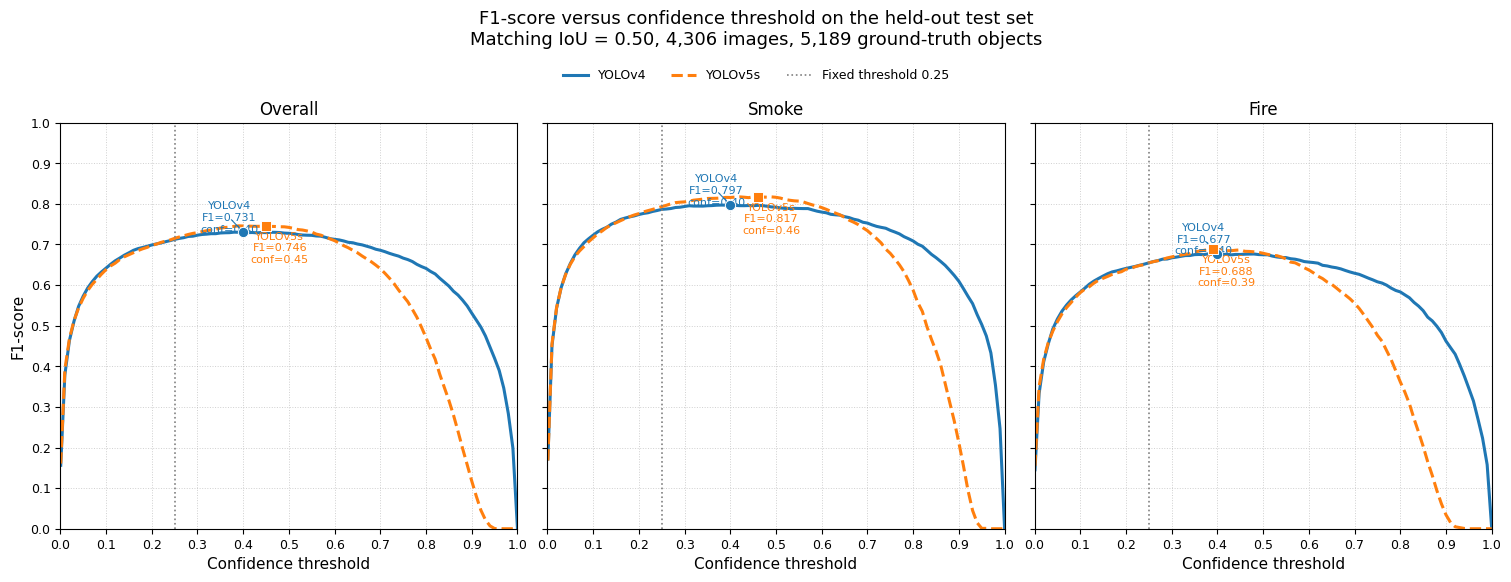


===== SAVED FIGURE FILES =====
PNG: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/figures/f1_score_vs_confidence_yolov4_yolov5.png
PNG exists: True
PDF: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/figures/f1_score_vs_confidence_yolov4_yolov5.pdf
PDF exists: True
Best-points CSV: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/best_f1_operating_points.csv
CSV exists: True
SUCCESS: The F1-confidence comparison figure was created.


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# --------------------------------------------------
# 1. Define the input and output files
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

COMPARISON_DIR = (
    PROJECT
    / "experiments"
    / "comparison"
)

FIGURE_DIR = COMPARISON_DIR / "figures"

FIGURE_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

CURVE_CSV = (
    COMPARISON_DIR
    / "yolov4_yolov5_f1_confidence_curves.csv"
)

OUTPUT_PNG = (
    FIGURE_DIR
    / "f1_score_vs_confidence_yolov4_yolov5.png"
)

OUTPUT_PDF = (
    FIGURE_DIR
    / "f1_score_vs_confidence_yolov4_yolov5.pdf"
)

BEST_POINTS_CSV = (
    COMPARISON_DIR
    / "best_f1_operating_points.csv"
)


# --------------------------------------------------
# 2. Load and validate the combined curve
# --------------------------------------------------

print("===== F1 GRAPH PRECHECK =====")
print("Combined curve CSV:", CURVE_CSV)
print("File exists:", CURVE_CSV.exists())

if not CURVE_CSV.exists():
    raise FileNotFoundError(
        "The combined confidence-curve CSV is missing."
    )

curve = pd.read_csv(CURVE_CSV)

required_columns = {
    "model",
    "class",
    "confidence",
    "precision",
    "recall",
    "f1_score",
}

missing_columns = required_columns - set(curve.columns)

if missing_columns:
    raise ValueError(
        f"Missing curve columns: {sorted(missing_columns)}"
    )

print("Rows loaded:", len(curve))
print("Expected rows: 606")
print("Models:", sorted(curve["model"].unique()))
print("Classes:", sorted(curve["class"].unique()))

if len(curve) != 606:
    raise RuntimeError(
        "The combined curve should contain 606 rows."
    )

# Stable model presentation across all future figures
model_styles = {
    "YOLOv4": {
        "color": "#1f77b4",
        "linestyle": "-",
        "marker": "o",
    },
    "YOLOv5s": {
        "color": "#ff7f0e",
        "linestyle": "--",
        "marker": "s",
    },
}

panel_configuration = [
    ("all", "Overall"),
    ("smoke", "Smoke"),
    ("fire", "Fire"),
]


# --------------------------------------------------
# 3. Find the best-F1 point for each model and class
# --------------------------------------------------

best_point_rows = []

print("\n===== BEST F1 POINTS USED IN GRAPH =====")

for class_name, panel_title in panel_configuration:
    for model_name in ["YOLOv4", "YOLOv5s"]:
        model_curve = curve[
            (curve["class"] == class_name)
            & (curve["model"] == model_name)
        ].sort_values("confidence")

        if len(model_curve) != 101:
            raise RuntimeError(
                f"Expected 101 points for "
                f"{model_name}, {class_name}; "
                f"found {len(model_curve)}."
            )

        best_index = model_curve["f1_score"].idxmax()
        best = model_curve.loc[best_index]

        best_point_rows.append({
            "model": model_name,
            "class": class_name,
            "best_confidence": best["confidence"],
            "precision_at_best_f1": best["precision"],
            "recall_at_best_f1": best["recall"],
            "best_f1_score": best["f1_score"],
        })

        print(
            f"{panel_title}, {model_name}: "
            f"confidence={best['confidence']:.2f}, "
            f"F1={best['f1_score']:.4f}"
        )

best_points = pd.DataFrame(best_point_rows)

best_points.to_csv(
    BEST_POINTS_CSV,
    index=False,
)


# --------------------------------------------------
# 4. Draw three panels: overall, smoke and fire
# --------------------------------------------------

print("\n===== CREATING FIGURE =====")

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 9,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 4.8),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for axis, (class_name, panel_title) in zip(
    axes,
    panel_configuration,
):
    for model_name in ["YOLOv4", "YOLOv5s"]:
        model_curve = curve[
            (curve["class"] == class_name)
            & (curve["model"] == model_name)
        ].sort_values("confidence")

        style = model_styles[model_name]

        axis.plot(
            model_curve["confidence"],
            model_curve["f1_score"],
            label=model_name,
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=2.2,
        )

        best_index = model_curve["f1_score"].idxmax()
        best = model_curve.loc[best_index]

        axis.scatter(
            best["confidence"],
            best["f1_score"],
            color=style["color"],
            marker=style["marker"],
            s=55,
            edgecolor="white",
            linewidth=0.7,
            zorder=5,
        )

        # Offset the two models' labels in opposite directions so they do not overlap
        horizontal_offset = (
            -0.03
            if model_name == "YOLOv4"
            else 0.03
        )

        vertical_offset = (
            0.035
            if model_name == "YOLOv4"
            else -0.055
        )

        annotation_x = np.clip(
            best["confidence"] + horizontal_offset,
            0.02,
            0.98,
        )

        annotation_y = np.clip(
            best["f1_score"] + vertical_offset,
            0.03,
            0.97,
        )

        axis.annotate(
            (
                f"{model_name}\n"
                f"F1={best['f1_score']:.3f}\n"
                f"conf={best['confidence']:.2f}"
            ),
            xy=(
                best["confidence"],
                best["f1_score"],
            ),
            xytext=(
                annotation_x,
                annotation_y,
            ),
            fontsize=8,
            color=style["color"],
            ha="center",
            va="center",
            arrowprops={
                "arrowstyle": "-",
                "color": style["color"],
                "linewidth": 0.8,
            },
        )

    # Mark the common fixed operating threshold
    axis.axvline(
        x=0.25,
        color="gray",
        linestyle=":",
        linewidth=1.2,
        label="Fixed threshold 0.25",
    )

    axis.set_title(panel_title)
    axis.set_xlabel("Confidence threshold")
    axis.set_xlim(0.0, 1.0)
    axis.set_ylim(0.0, 1.0)
    axis.set_xticks(np.arange(0.0, 1.01, 0.1))
    axis.set_yticks(np.arange(0.0, 1.01, 0.1))
    axis.grid(
        True,
        linestyle=":",
        linewidth=0.7,
        alpha=0.6,
    )

axes[0].set_ylabel("F1-score")

# Use one shared legend to avoid repeating it in every panel
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.08),
    ncol=3,
    frameon=False,
)

fig.suptitle(
    (
        "F1-score versus confidence threshold on the "
        "held-out test set\n"
        "Matching IoU = 0.50, 4,306 images, "
        "5,189 ground-truth objects"
    ),
    fontsize=13,
    y=1.18,
)


# --------------------------------------------------
# 5. Save as PNG (300 dpi) and PDF
# --------------------------------------------------

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_PDF,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("\n===== SAVED FIGURE FILES =====")
print("PNG:", OUTPUT_PNG)
print("PNG exists:", OUTPUT_PNG.exists())
print("PDF:", OUTPUT_PDF)
print("PDF exists:", OUTPUT_PDF.exists())
print("Best-points CSV:", BEST_POINTS_CSV)
print("CSV exists:", BEST_POINTS_CSV.exists())

if (
    OUTPUT_PNG.exists()
    and OUTPUT_PDF.exists()
    and BEST_POINTS_CSV.exists()
):
    print(
        "SUCCESS: The F1-confidence comparison "
        "figure was created."
    )
else:
    print(
        "One or more graph outputs are missing."
    )

### 6.2 Final test-set metrics

===== FINAL-METRICS GRAPH PRECHECK =====
Metrics CSV: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/yolov4_yolov5_test_metrics_standardized.csv
File exists: True
Rows loaded: 6
Models: ['YOLOv4', 'YOLOv5s']
Classes: ['all', 'fire', 'smoke']

===== OVERALL VALUES USED =====
            ap50  precision_conf025  recall_conf025  f1_conf025
model                                                          
YOLOv4  0.746340           0.688533        0.738293    0.712545
YOLOv5s 0.760000           0.673303        0.762575    0.715164

===== CLASS AP50 VALUES USED =====
  model class     ap50
 YOLOv4  fire 0.685100
YOLOv5s  fire 0.692000
 YOLOv4 smoke 0.807600
YOLOv5s smoke 0.829000

===== CREATING FINAL TEST-METRICS FIGURE =====


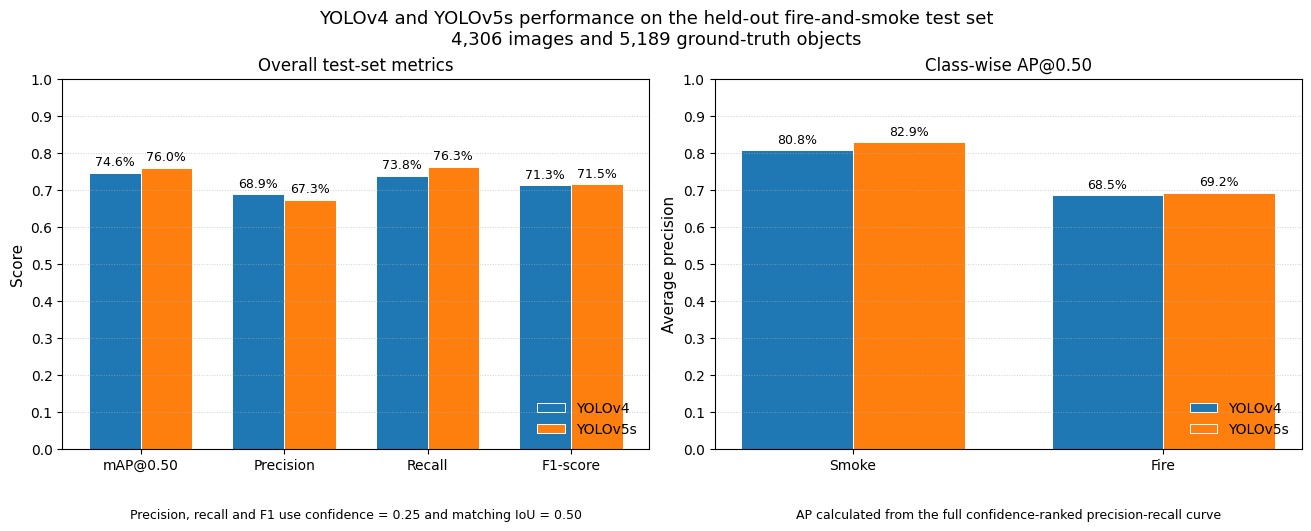


===== SAVED FINAL-METRICS FIGURE =====
PNG: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/figures/final_test_metrics_yolov4_yolov5.png
PNG exists: True
PDF: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/figures/final_test_metrics_yolov4_yolov5.pdf
PDF exists: True
SUCCESS: The final test-set metric comparison figure was created.


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# --------------------------------------------------
# 1. Define the input and output files
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

COMPARISON_DIR = (
    PROJECT
    / "experiments"
    / "comparison"
)

FIGURE_DIR = COMPARISON_DIR / "figures"

METRICS_CSV = (
    COMPARISON_DIR
    / "yolov4_yolov5_test_metrics_standardized.csv"
)

OUTPUT_PNG = (
    FIGURE_DIR
    / "final_test_metrics_yolov4_yolov5.png"
)

OUTPUT_PDF = (
    FIGURE_DIR
    / "final_test_metrics_yolov4_yolov5.pdf"
)


# --------------------------------------------------
# 2. Load and validate the standardised metrics
# --------------------------------------------------

print("===== FINAL-METRICS GRAPH PRECHECK =====")
print("Metrics CSV:", METRICS_CSV)
print("File exists:", METRICS_CSV.exists())

if not METRICS_CSV.exists():
    raise FileNotFoundError(
        "The standardized metrics CSV is missing."
    )

metrics = pd.read_csv(METRICS_CSV)

required_columns = {
    "model",
    "class",
    "ap50",
    "precision_conf025",
    "recall_conf025",
    "f1_conf025",
}

missing_columns = required_columns - set(metrics.columns)

if missing_columns:
    raise ValueError(
        f"Missing metric columns: {sorted(missing_columns)}"
    )

print("Rows loaded:", len(metrics))
print("Models:", sorted(metrics["model"].unique()))
print("Classes:", sorted(metrics["class"].unique()))


# --------------------------------------------------
# 3. Separate the overall rows from the per-class rows
# --------------------------------------------------

model_order = ["YOLOv4", "YOLOv5s"]

model_colors = {
    "YOLOv4": "#1f77b4",
    "YOLOv5s": "#ff7f0e",
}

overall = (
    metrics[
        metrics["class"] == "all"
    ]
    .set_index("model")
    .loc[model_order]
)

class_metrics = metrics[
    metrics["class"].isin(["smoke", "fire"])
].copy()

print("\n===== OVERALL VALUES USED =====")

print(
    overall[
        [
            "ap50",
            "precision_conf025",
            "recall_conf025",
            "f1_conf025",
        ]
    ].to_string(
        float_format=lambda value: f"{value:.6f}",
    )
)

print("\n===== CLASS AP50 VALUES USED =====")

print(
    class_metrics[
        [
            "model",
            "class",
            "ap50",
        ]
    ].sort_values(
        ["class", "model"]
    ).to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)


# --------------------------------------------------
# 4. Draw two panels: overall metrics and class-wise AP
# --------------------------------------------------

print("\n===== CREATING FINAL TEST-METRICS FIGURE =====")

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
})

fig, axes = plt.subplots(
    nrows=1,
    ncols=2,
    figsize=(13, 5.2),
    constrained_layout=True,
)

# Panel 1: Overall metrics
overall_metric_columns = [
    "ap50",
    "precision_conf025",
    "recall_conf025",
    "f1_conf025",
]

overall_metric_labels = [
    "mAP@0.50",
    "Precision",
    "Recall",
    "F1-score",
]

x_positions = np.arange(
    len(overall_metric_columns)
)

bar_width = 0.36

for model_index, model_name in enumerate(model_order):
    values = (
        overall
        .loc[model_name, overall_metric_columns]
        .astype(float)
        .to_numpy()
    )

    # Shift each model's bars half a bar-width left or right of the tick
    positions = (
        x_positions
        + (model_index - 0.5) * bar_width
    )

    bars = axes[0].bar(
        positions,
        values,
        width=bar_width,
        label=model_name,
        color=model_colors[model_name],
        edgecolor="white",
        linewidth=0.7,
    )

    axes[0].bar_label(
        bars,
        labels=[
            f"{value * 100:.1f}%"
            for value in values
        ],
        padding=3,
        fontsize=9,
    )

axes[0].set_title("Overall test-set metrics")
axes[0].set_ylabel("Score")
axes[0].set_xticks(
    x_positions,
    overall_metric_labels,
)
axes[0].set_ylim(0.0, 1.0)
axes[0].set_yticks(
    np.arange(0.0, 1.01, 0.1)
)
axes[0].grid(
    axis="y",
    linestyle=":",
    linewidth=0.7,
    alpha=0.6,
)
axes[0].legend(
    loc="lower right",
    frameon=False,
)

axes[0].text(
    0.5,
    -0.16,
    (
        "Precision, recall and F1 use confidence = 0.25 "
        "and matching IoU = 0.50"
    ),
    transform=axes[0].transAxes,
    ha="center",
    va="top",
    fontsize=9,
)

# Panel 2: Class-wise AP50
class_order = ["smoke", "fire"]
class_labels = ["Smoke", "Fire"]
class_positions = np.arange(len(class_order))

for model_index, model_name in enumerate(model_order):
    values = []

    for class_name in class_order:
        matching_row = class_metrics[
            (class_metrics["model"] == model_name)
            & (class_metrics["class"] == class_name)
        ]

        if len(matching_row) != 1:
            raise RuntimeError(
                f"Expected one row for "
                f"{model_name}, {class_name}."
            )

        values.append(
            float(matching_row.iloc[0]["ap50"])
        )

    positions = (
        class_positions
        + (model_index - 0.5) * bar_width
    )

    bars = axes[1].bar(
        positions,
        values,
        width=bar_width,
        label=model_name,
        color=model_colors[model_name],
        edgecolor="white",
        linewidth=0.7,
    )

    axes[1].bar_label(
        bars,
        labels=[
            f"{value * 100:.1f}%"
            for value in values
        ],
        padding=3,
        fontsize=9,
    )

axes[1].set_title("Class-wise AP@0.50")
axes[1].set_ylabel("Average precision")
axes[1].set_xticks(
    class_positions,
    class_labels,
)
axes[1].set_ylim(0.0, 1.0)
axes[1].set_yticks(
    np.arange(0.0, 1.01, 0.1)
)
axes[1].grid(
    axis="y",
    linestyle=":",
    linewidth=0.7,
    alpha=0.6,
)
axes[1].legend(
    loc="lower right",
    frameon=False,
)

axes[1].text(
    0.5,
    -0.16,
    (
        "AP calculated from the full confidence-ranked "
        "precision-recall curve"
    ),
    transform=axes[1].transAxes,
    ha="center",
    va="top",
    fontsize=9,
)

fig.suptitle(
    (
        "YOLOv4 and YOLOv5s performance on the "
        "held-out fire-and-smoke test set\n"
        "4,306 images and 5,189 ground-truth objects"
    ),
    fontsize=13,
)


# --------------------------------------------------
# 5. Save as PNG (300 dpi) and PDF
# --------------------------------------------------

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_PDF,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("\n===== SAVED FINAL-METRICS FIGURE =====")
print("PNG:", OUTPUT_PNG)
print("PNG exists:", OUTPUT_PNG.exists())
print("PDF:", OUTPUT_PDF)
print("PDF exists:", OUTPUT_PDF.exists())

if OUTPUT_PNG.exists() and OUTPUT_PDF.exists():
    print(
        "SUCCESS: The final test-set metric "
        "comparison figure was created."
    )
else:
    print(
        "One or more figure files are missing."
    )

## 7. Training history

### 7.1 Find the training-history sources for both models

In [ ]:
from pathlib import Path
import re
import pandas as pd


# --------------------------------------------------
# 1. Define the paths
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

YOLOV4_EXPERIMENT = (
    PROJECT
    / "experiments"
    / "YOLOv4"
)

YOLOV5_RESULTS = (
    PROJECT
    / "experiments"
    / "YOLOv5"
    / "yolov5s_corrected_416_85"
    / "results.csv"
)


# --------------------------------------------------
# 2. YOLOv5 history
# --------------------------------------------------
#
# YOLOv5 writes one row per epoch to results.csv.
# --------------------------------------------------

print("===== YOLOV5 HISTORY CHECK =====")
print("results.csv:", YOLOV5_RESULTS)
print("Exists:", YOLOV5_RESULTS.exists())

if YOLOV5_RESULTS.exists():
    yolov5_results = pd.read_csv(YOLOV5_RESULTS)
    yolov5_results.columns = [
        column.strip()
        for column in yolov5_results.columns
    ]

    print("Epoch rows:", len(yolov5_results))
    print("Columns:")

    for column in yolov5_results.columns:
        print(" ", column)
else:
    print("YOLOv5 results.csv is missing.")


# --------------------------------------------------
# 3. YOLOv4 history
# --------------------------------------------------
#
# Darknet has no results file. Its validation metrics exist only
# as text inside the console logs, so search those logs.
# --------------------------------------------------

print("\n===== YOLOV4 HISTORY FILE SEARCH =====")

candidate_extensions = {
    ".log",
    ".txt",
    ".csv",
}

candidate_files = sorted(
    path
    for path in YOLOV4_EXPERIMENT.rglob("*")
    if path.is_file()
    and path.suffix.lower() in candidate_extensions
)

print("Candidate files found:", len(candidate_files))

# Text patterns that mark training-history lines in Darknet output
patterns = {
    "iteration": re.compile(
        r"^\s*\d+\s*:"
    ),
    "map": re.compile(
        r"mAP@0\.50|mean average precision",
        re.IGNORECASE,
    ),
    "precision_recall": re.compile(
        r"precision\s*=.*recall\s*=.*F1",
        re.IGNORECASE,
    ),
    "last_accuracy": re.compile(
        r"Last accuracy",
        re.IGNORECASE,
    ),
}

useful_files = []

for path in candidate_files:
    try:
        text = path.read_text(
            encoding="utf-8",
            errors="replace",
        )
    except Exception as error:
        print("Could not read:", path, repr(error))
        continue

    counts = {
        name: len(pattern.findall(text))
        for name, pattern in patterns.items()
    }

    if any(counts.values()):
        useful_files.append({
            "path": path,
            "size_mb": path.stat().st_size / 1024**2,
            **counts,
        })

print("\n===== USEFUL YOLOV4 HISTORY FILES =====")

if not useful_files:
    print(
        "No YOLOv4 files containing training-history "
        "patterns were found."
    )

for item in useful_files:
    print("\nFile:", item["path"])
    print(f"Size: {item['size_mb']:.2f} MB")
    print("Iteration lines:", item["iteration"])
    print("mAP lines:", item["map"])
    print(
        "Precision/recall/F1 lines:",
        item["precision_recall"],
    )
    print(
        "Last-accuracy lines:",
        item["last_accuracy"],
    )


# --------------------------------------------------
# 4. Show sample metric lines from each useful file
# --------------------------------------------------

print("\n===== SAMPLE YOLOV4 METRIC LINES =====")

for item in useful_files:
    path = item["path"]

    text_lines = path.read_text(
        encoding="utf-8",
        errors="replace",
    ).splitlines()

    matching_lines = [
        line.strip()
        for line in text_lines
        if (
            patterns["last_accuracy"].search(line)
            or patterns["precision_recall"].search(line)
            or patterns["map"].search(line)
        )
    ]

    if not matching_lines:
        continue

    print("\nFile:", path)
    print("First five metric lines:")

    for line in matching_lines[:5]:
        print(line)

    print("Last five metric lines:")

    for line in matching_lines[-5:]:
        print(line)

print("\n===== AUDIT SUMMARY =====")
print("YOLOv5 epoch history available:", YOLOV5_RESULTS.exists())
print(
    "YOLOv4 useful history files:",
    len(useful_files),
)

if YOLOV5_RESULTS.exists() and useful_files:
    print(
        "SUCCESS: Training-history sources are available "
        "for both models."
    )
else:
    print(
        "One model's training history needs further "
        "investigation before plotting."
    )

===== YOLOV5 HISTORY CHECK =====
results.csv: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv5/yolov5s_corrected_416_85/results.csv
Exists: True
Epoch rows: 85
Columns:
  epoch
  train/box_loss
  train/obj_loss
  train/cls_loss
  metrics/precision
  metrics/recall
  metrics/mAP_0.5
  metrics/mAP_0.5:0.95
  val/box_loss
  val/obj_loss
  val/cls_loss
  x/lr0
  x/lr1
  x/lr2

===== YOLOV4 HISTORY FILE SEARCH =====
Candidate files found: 10

===== USEFUL YOLOV4 HISTORY FILES =====

File: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/logs/yolov4_training.log
Size: 163.50 MB
Iteration lines: 0
mAP lines: 14042
Precision/recall/F1 lines: 19
Last-accuracy lines: 13966

File: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/results/yolov4_test_conf025_iou050.txt
Size: 0.02 MB
Iteration lines: 0
mAP lines: 3
Precision/recall/F1 lines: 1
Last-accuracy lines: 0

File: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/results/yolov4_test_map

### 7.2 Extract the 19 YOLOv4 validation events from the training log

In [ ]:
from pathlib import Path
import re
from bisect import bisect_left
import pandas as pd


# --------------------------------------------------
# 1. Define the paths and training constants
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

TRAINING_LOG = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "logs"
    / "yolov4_training.log"
)

COMPARISON_DIR = (
    PROJECT
    / "experiments"
    / "comparison"
)

OUTPUT_CSV = (
    COMPARISON_DIR
    / "yolov4_validation_history.csv"
)

# Used to convert Darknet iterations to epochs. One iteration is one
# batch of 64 images, so epoch = iteration x 64 / 13,777.
TRAINING_IMAGES = 13777
DARKNET_BATCH = 64
MAX_BATCHES = 18298


# --------------------------------------------------
# 2. Load the training log
# --------------------------------------------------

print("===== CORRECTED YOLOV4 HISTORY PRECHECK =====")
print("Training log:", TRAINING_LOG)
print("Exists:", TRAINING_LOG.exists())

if not TRAINING_LOG.exists():
    raise FileNotFoundError(
        "The YOLOv4 training log is missing."
    )

lines = TRAINING_LOG.read_text(
    encoding="utf-8",
    errors="replace",
).splitlines()

print("Stored log lines:", len(lines))


# --------------------------------------------------
# 3. Patterns for the three kinds of log line
# --------------------------------------------------
#
# precision/recall line, mAP line and the iteration counter
# --------------------------------------------------

precision_recall_pattern = re.compile(
    r"for\s+conf_thresh\s*=\s*"
    r"([0-9.eE+-]+)\s*,\s*"
    r"precision\s*=\s*([0-9.eE+-]+)\s*,\s*"
    r"recall\s*=\s*([0-9.eE+-]+)\s*,\s*"
    r"F1-score\s*=\s*([0-9.eE+-]+)",
    re.IGNORECASE,
)

map_pattern = re.compile(
    r"mean average precision\s*"
    r"\(mAP@0\.50\)\s*=\s*"
    r"([0-9.eE+-]+)",
    re.IGNORECASE,
)

# This broader expression does not require
# "Last accuracy" to be stored on the same line.
iteration_pattern = re.compile(
    r"H?\s*(\d+)\s*/\s*18298",
    re.IGNORECASE,
)


# --------------------------------------------------
# 4. Scan the log once and record where each kind of line occurs
# --------------------------------------------------

print("\n===== INDEXING LOG MARKERS =====")

metric_markers = []
map_markers = []
iteration_markers = []

for line_index, line in enumerate(lines):
    metric_match = precision_recall_pattern.search(line)

    if metric_match:
        metric_markers.append(
            (line_index, metric_match)
        )

    map_match = map_pattern.search(line)

    if map_match:
        map_markers.append(
            (
                line_index,
                float(map_match.group(1)),
            )
        )

    iteration_match = iteration_pattern.search(line)

    if iteration_match:
        iteration = int(
            iteration_match.group(1)
        )

        if 0 <= iteration <= MAX_BATCHES:
            iteration_markers.append(
                (
                    line_index,
                    iteration,
                )
            )

print("Precision/recall markers:", len(metric_markers))
print("mAP markers:", len(map_markers))
print("Iteration markers:", len(iteration_markers))

if len(metric_markers) != 19:
    raise RuntimeError(
        "Expected 19 precision/recall events."
    )

if not map_markers:
    raise RuntimeError(
        "No mAP markers were found."
    )

if not iteration_markers:
    raise RuntimeError(
        "No Darknet iteration markers were found."
    )

map_line_indices = [
    item[0]
    for item in map_markers
]

iteration_line_indices = [
    item[0]
    for item in iteration_markers
]


# --------------------------------------------------
# 5. Helper: find the marker closest to a given log line
# --------------------------------------------------
#
# Darknet prints the mAP value and the iteration counter on different
# lines from the precision/recall line, so each validation event is
# paired with the nearest mAP and iteration markers.
# --------------------------------------------------

def nearest_marker(
    target_line,
    markers,
    marker_line_indices,
):
    """
    Find the marker whose stored line is nearest
    to the requested metric line.
    """
    insertion_position = bisect_left(
        marker_line_indices,
        target_line,
    )

    candidate_positions = []

    if insertion_position < len(markers):
        candidate_positions.append(
            insertion_position
        )

    if insertion_position > 0:
        candidate_positions.append(
            insertion_position - 1
        )

    if not candidate_positions:
        raise RuntimeError(
            "No nearby marker candidate was found."
        )

    best_position = min(
        candidate_positions,
        key=lambda position: abs(
            markers[position][0] - target_line
        ),
    )

    return markers[best_position]


# --------------------------------------------------
# 6. Build one row per validation event
# --------------------------------------------------

print("\n===== EXTRACTING 19 VALIDATION EVENTS =====")

events = []

for event_number, (
    metric_line_index,
    metric_match,
) in enumerate(
    metric_markers,
    start=1,
):
    confidence_threshold = float(
        metric_match.group(1)
    )

    precision = float(
        metric_match.group(2)
    )

    recall = float(
        metric_match.group(3)
    )

    f1_score = float(
        metric_match.group(4)
    )

    map_line_index, map50 = nearest_marker(
        metric_line_index,
        map_markers,
        map_line_indices,
    )

    (
        iteration_line_index,
        iteration,
    ) = nearest_marker(
        metric_line_index,
        iteration_markers,
        iteration_line_indices,
    )

    equivalent_epoch = (
        iteration
        * DARKNET_BATCH
        / TRAINING_IMAGES
    )

    events.append({
        "validation_event": event_number,
        "iteration": iteration,
        "equivalent_epoch": equivalent_epoch,
        "confidence_threshold": confidence_threshold,
        "precision": precision,
        "recall": recall,
        "f1_score": f1_score,
        "map50": map50,
        "metric_log_line": metric_line_index + 1,
        "map_log_line": map_line_index + 1,
        "iteration_log_line": iteration_line_index + 1,
    })

history = pd.DataFrame(events)

history = history.sort_values(
    by=[
        "iteration",
        "validation_event",
    ]
).reset_index(drop=True)

print("\n===== EXTRACTED HISTORY =====")

display_columns = [
    "validation_event",
    "iteration",
    "equivalent_epoch",
    "confidence_threshold",
    "precision",
    "recall",
    "f1_score",
    "map50",
]

print(
    history[display_columns].to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)


# --------------------------------------------------
# 7. Validate the extracted history
# --------------------------------------------------

print("\n===== EXTRACTION VALIDATION =====")
print("Extracted rows:", len(history))
print("Expected rows: 19")
print("Unique iterations:", history["iteration"].nunique())
print(
    "Iteration order valid:",
    history["iteration"].is_monotonic_increasing,
)

print(
    "Iterations:",
    history["iteration"].tolist(),
)

print(
    "First equivalent epoch:",
    f"{history['equivalent_epoch'].iloc[0]:.3f}",
)

print(
    "Last equivalent epoch:",
    f"{history['equivalent_epoch'].iloc[-1]:.3f}",
)

print(
    "Final extracted mAP@0.50:",
    f"{history['map50'].iloc[-1]:.6f}",
)

EXPECTED_FINAL_MAP = 0.752377

print(
    "Expected final mAP@0.50:",
    f"{EXPECTED_FINAL_MAP:.6f}",
)

final_map_matches = (
    abs(
        history["map50"].iloc[-1]
        - EXPECTED_FINAL_MAP
    )
    < 1e-6
)

print("Final mAP matches:", final_map_matches)

# Each validation event should normally have a distinct iteration.
iterations_are_valid = (
    history["iteration"].nunique()
    == len(history)
    and history["iteration"].is_monotonic_increasing
)

if not iterations_are_valid:
    print(
        "\nWARNING: The nearest iteration mapping "
        "contains duplicates or ordering problems."
    )
    print(
        "Do not use the extracted history for plotting yet."
    )


# --------------------------------------------------
# 8. Save the history
# --------------------------------------------------

COMPARISON_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

history.to_csv(
    OUTPUT_CSV,
    index=False,
)

print("\n===== SAVED YOLOV4 HISTORY =====")
print("History CSV:", OUTPUT_CSV)
print("File exists:", OUTPUT_CSV.exists())

if (
    OUTPUT_CSV.exists()
    and len(history) == 19
    and iterations_are_valid
    and final_map_matches
):
    print(
        "SUCCESS: The 19 measured YOLOv4 validation "
        "events were extracted correctly."
    )
else:
    print(
        "The extracted history requires another "
        "validation step before plotting."
    )

===== CORRECTED YOLOV4 HISTORY PRECHECK =====
Training log: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/logs/yolov4_training.log
Exists: True
Stored log lines: 1329912

===== INDEXING LOG MARKERS =====
Precision/recall markers: 19
mAP markers: 19
Iteration markers: 18410

===== EXTRACTING 19 VALIDATION EVENTS =====

===== EXTRACTED HISTORY =====
 validation_event  iteration  equivalent_epoch  confidence_threshold  precision   recall  f1_score    map50
                1       1000          4.645424              0.250000   0.490000 0.420000  0.450000 0.409595
                2       1861          8.645133              0.250000   0.600000 0.560000  0.580000 0.602214
                3       3461         16.077811              0.250000   0.690000 0.630000  0.660000 0.679865
                4       4322         20.077521              0.250000   0.680000 0.690000  0.690000 0.721168
                5       5183         24.077230              0.250000   0.720000 0.620000  0.6

### 7.3 Validation mAP, precision and recall against epoch

===== VALIDATION-GRAPH PRECHECK =====
YOLOv4 history: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/yolov4_validation_history.csv -> True
YOLOv5 results: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv5/yolov5s_corrected_416_85/results.csv -> True

===== HISTORY COUNTS =====
YOLOv4 measured validation points: 19
YOLOv5 measured validation points: 85
Expected YOLOv4 points: 19
Expected YOLOv5 points: 85

===== VALIDATION SUMMARY =====
                                 metric   model  final_value  best_value  best_epoch  points_recorded  directly_comparable
                    Validation mAP@0.50  YOLOv4     0.752377    0.752377   85.001960               19                 True
                    Validation mAP@0.50 YOLOv5s     0.765290    0.768300   75.000000               85                 True
Framework-reported validation precision  YOLOv4     0.720000    0.730000   35.124047               19                False
Framework-reported validation preci

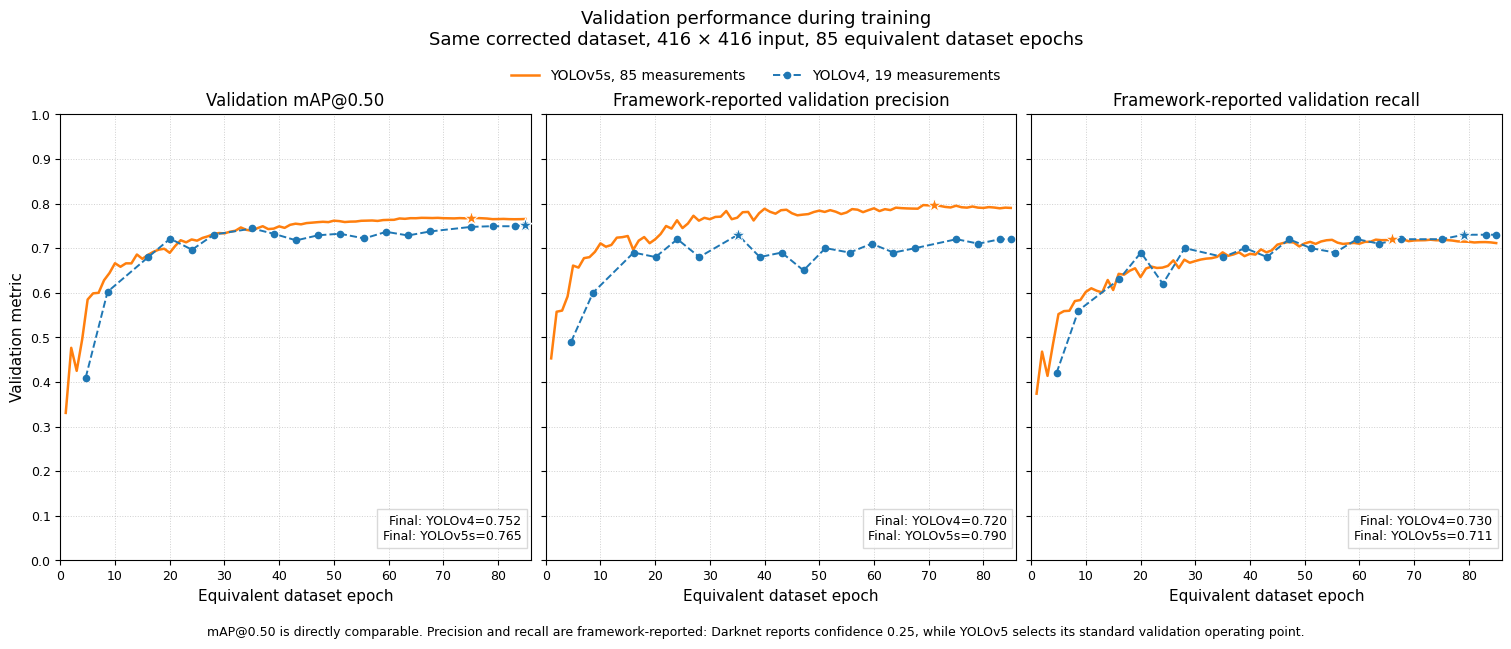


===== SAVED VALIDATION FIGURE =====
PNG: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/figures/validation_metrics_vs_epoch_yolov4_yolov5.png
PNG exists: True
PDF: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/figures/validation_metrics_vs_epoch_yolov4_yolov5.pdf
PDF exists: True
Summary CSV: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/validation_history_summary.csv
Summary exists: True
SUCCESS: Validation mAP, precision and recall figures were created.


In [ ]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np


# --------------------------------------------------
# 1. Define the input and output files
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

COMPARISON_DIR = (
    PROJECT
    / "experiments"
    / "comparison"
)

FIGURE_DIR = COMPARISON_DIR / "figures"

YOLOV4_HISTORY_CSV = (
    COMPARISON_DIR
    / "yolov4_validation_history.csv"
)

YOLOV5_RESULTS_CSV = (
    PROJECT
    / "experiments"
    / "YOLOv5"
    / "yolov5s_corrected_416_85"
    / "results.csv"
)

OUTPUT_PNG = (
    FIGURE_DIR
    / "validation_metrics_vs_epoch_yolov4_yolov5.png"
)

OUTPUT_PDF = (
    FIGURE_DIR
    / "validation_metrics_vs_epoch_yolov4_yolov5.pdf"
)

SUMMARY_CSV = (
    COMPARISON_DIR
    / "validation_history_summary.csv"
)


# --------------------------------------------------
# 2. Load and validate both histories
# --------------------------------------------------

print("===== VALIDATION-GRAPH PRECHECK =====")
print(
    "YOLOv4 history:",
    YOLOV4_HISTORY_CSV,
    "->",
    YOLOV4_HISTORY_CSV.exists(),
)
print(
    "YOLOv5 results:",
    YOLOV5_RESULTS_CSV,
    "->",
    YOLOV5_RESULTS_CSV.exists(),
)

if not YOLOV4_HISTORY_CSV.exists():
    raise FileNotFoundError(
        "The YOLOv4 validation-history CSV is missing."
    )

if not YOLOV5_RESULTS_CSV.exists():
    raise FileNotFoundError(
        "The YOLOv5 results.csv file is missing."
    )

yolov4 = pd.read_csv(YOLOV4_HISTORY_CSV)
yolov5 = pd.read_csv(YOLOV5_RESULTS_CSV)

yolov5.columns = [
    column.strip()
    for column in yolov5.columns
]

required_yolov4_columns = {
    "equivalent_epoch",
    "map50",
    "precision",
    "recall",
}

required_yolov5_columns = {
    "epoch",
    "metrics/mAP_0.5",
    "metrics/precision",
    "metrics/recall",
}

missing_yolov4 = (
    required_yolov4_columns
    - set(yolov4.columns)
)

missing_yolov5 = (
    required_yolov5_columns
    - set(yolov5.columns)
)

if missing_yolov4:
    raise ValueError(
        f"Missing YOLOv4 columns: "
        f"{sorted(missing_yolov4)}"
    )

if missing_yolov5:
    raise ValueError(
        f"Missing YOLOv5 columns: "
        f"{sorted(missing_yolov5)}"
    )

# Convert YOLOv5 zero-based epoch numbers into
# human-readable research epochs 1 to 85.
yolov5["research_epoch"] = (
    yolov5["epoch"].astype(float) + 1
)

print("\n===== HISTORY COUNTS =====")
print("YOLOv4 measured validation points:", len(yolov4))
print("YOLOv5 measured validation points:", len(yolov5))
print("Expected YOLOv4 points: 19")
print("Expected YOLOv5 points: 85")

if len(yolov4) != 19 or len(yolov5) != 85:
    raise RuntimeError(
        "Unexpected validation-history length."
    )


# --------------------------------------------------
# 3. One entry per panel
# --------------------------------------------------
#
# Precision and recall are marked as not directly comparable because
# the two frameworks report them at different confidence thresholds.
# --------------------------------------------------

metric_configuration = [
    {
        "title": "Validation mAP@0.50",
        "y_label": "mAP@0.50",
        "yolov4_column": "map50",
        "yolov5_column": "metrics/mAP_0.5",
        "directly_comparable": True,
    },
    {
        "title": "Framework-reported validation precision",
        "y_label": "Precision",
        "yolov4_column": "precision",
        "yolov5_column": "metrics/precision",
        "directly_comparable": False,
    },
    {
        "title": "Framework-reported validation recall",
        "y_label": "Recall",
        "yolov4_column": "recall",
        "yolov5_column": "metrics/recall",
        "directly_comparable": False,
    },
]

model_colors = {
    "YOLOv4": "#1f77b4",
    "YOLOv5s": "#ff7f0e",
}


# --------------------------------------------------
# 4. Final and best value of each metric for each model
# --------------------------------------------------

summary_rows = []

print("\n===== VALIDATION SUMMARY =====")

for configuration in metric_configuration:
    yolov4_values = yolov4[
        configuration["yolov4_column"]
    ].astype(float)

    yolov5_values = yolov5[
        configuration["yolov5_column"]
    ].astype(float)

    yolov4_best_index = yolov4_values.idxmax()
    yolov5_best_index = yolov5_values.idxmax()

    summary_rows.extend([
        {
            "metric": configuration["title"],
            "model": "YOLOv4",
            "final_value": yolov4_values.iloc[-1],
            "best_value": yolov4_values.loc[
                yolov4_best_index
            ],
            "best_epoch": yolov4.loc[
                yolov4_best_index,
                "equivalent_epoch",
            ],
            "points_recorded": len(yolov4),
            "directly_comparable": (
                configuration["directly_comparable"]
            ),
        },
        {
            "metric": configuration["title"],
            "model": "YOLOv5s",
            "final_value": yolov5_values.iloc[-1],
            "best_value": yolov5_values.loc[
                yolov5_best_index
            ],
            "best_epoch": yolov5.loc[
                yolov5_best_index,
                "research_epoch",
            ],
            "points_recorded": len(yolov5),
            "directly_comparable": (
                configuration["directly_comparable"]
            ),
        },
    ])

summary = pd.DataFrame(summary_rows)

print(
    summary.to_string(
        index=False,
        float_format=lambda value: f"{value:.6f}",
    )
)

summary.to_csv(
    SUMMARY_CSV,
    index=False,
)


# --------------------------------------------------
# 5. Draw the three panels
# --------------------------------------------------

print("\n===== CREATING VALIDATION FIGURE =====")

plt.rcParams.update({
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
    "legend.fontsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
})

fig, axes = plt.subplots(
    nrows=1,
    ncols=3,
    figsize=(15, 5.2),
    sharex=True,
    sharey=True,
    constrained_layout=True,
)

for axis, configuration in zip(
    axes,
    metric_configuration,
):
    yolov4_values = yolov4[
        configuration["yolov4_column"]
    ].astype(float)

    yolov5_values = yolov5[
        configuration["yolov5_column"]
    ].astype(float)

    # YOLOv5 has one recorded point per epoch.
    axis.plot(
        yolov5["research_epoch"],
        yolov5_values,
        color=model_colors["YOLOv5s"],
        linewidth=1.8,
        label="YOLOv5s, 85 measurements",
        zorder=2,
    )

    # YOLOv4 is shown with visible markers because
    # only 19 validation events were measured.
    axis.plot(
        yolov4["equivalent_epoch"],
        yolov4_values,
        color=model_colors["YOLOv4"],
        linewidth=1.4,
        linestyle="--",
        marker="o",
        markersize=4.5,
        label="YOLOv4, 19 measurements",
        zorder=3,
    )

    yolov4_best_index = yolov4_values.idxmax()
    yolov5_best_index = yolov5_values.idxmax()

    axis.scatter(
        yolov4.loc[
            yolov4_best_index,
            "equivalent_epoch",
        ],
        yolov4_values.loc[yolov4_best_index],
        color=model_colors["YOLOv4"],
        marker="*",
        s=110,
        edgecolor="white",
        linewidth=0.7,
        zorder=5,
    )

    axis.scatter(
        yolov5.loc[
            yolov5_best_index,
            "research_epoch",
        ],
        yolov5_values.loc[yolov5_best_index],
        color=model_colors["YOLOv5s"],
        marker="*",
        s=110,
        edgecolor="white",
        linewidth=0.7,
        zorder=5,
    )

    axis.set_title(configuration["title"])
    axis.set_xlabel("Equivalent dataset epoch")
    axis.set_xlim(0, 86)
    axis.set_ylim(0, 1.0)
    axis.set_xticks(
        np.arange(0, 86, 10)
    )
    axis.set_yticks(
        np.arange(0, 1.01, 0.1)
    )
    axis.grid(
        True,
        linestyle=":",
        linewidth=0.7,
        alpha=0.6,
    )

    axis.text(
        0.98,
        0.04,
        (
            f"Final: YOLOv4={yolov4_values.iloc[-1]:.3f}\n"
            f"Final: YOLOv5s={yolov5_values.iloc[-1]:.3f}"
        ),
        transform=axis.transAxes,
        ha="right",
        va="bottom",
        fontsize=9,
        bbox={
            "facecolor": "white",
            "edgecolor": "lightgray",
            "alpha": 0.85,
        },
    )

axes[0].set_ylabel("Validation metric")

handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.06),
    ncol=2,
    frameon=False,
)

fig.suptitle(
    (
        "Validation performance during training\n"
        "Same corrected dataset, 416 × 416 input, "
        "85 equivalent dataset epochs"
    ),
    fontsize=13,
    y=1.15,
)

fig.text(
    0.5,
    -0.035,
    (
        "mAP@0.50 is directly comparable. "
        "Precision and recall are framework-reported: "
        "Darknet reports confidence 0.25, while YOLOv5 "
        "selects its standard validation operating point."
    ),
    ha="center",
    va="top",
    fontsize=9,
)


# --------------------------------------------------
# 6. Save as PNG (300 dpi) and PDF
# --------------------------------------------------

fig.savefig(
    OUTPUT_PNG,
    dpi=300,
    bbox_inches="tight",
)

fig.savefig(
    OUTPUT_PDF,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

print("\n===== SAVED VALIDATION FIGURE =====")
print("PNG:", OUTPUT_PNG)
print("PNG exists:", OUTPUT_PNG.exists())
print("PDF:", OUTPUT_PDF)
print("PDF exists:", OUTPUT_PDF.exists())
print("Summary CSV:", SUMMARY_CSV)
print("Summary exists:", SUMMARY_CSV.exists())

if (
    OUTPUT_PNG.exists()
    and OUTPUT_PDF.exists()
    and SUMMARY_CSV.exists()
):
    print(
        "SUCCESS: Validation mAP, precision and recall "
        "figures were created."
    )
else:
    print(
        "One or more validation-figure files are missing."
    )

## 8. Inference speed

### 8.1 Prepare a fixed benchmark sample

210 test images spread evenly across the sorted test set: 10 for warm-up, 200 measured. Both models are timed
on this same sample.

In [ ]:
from pathlib import Path
import numpy as np
import os


# --------------------------------------------------
# 1. Define the paths
# --------------------------------------------------
#
# The symbolic links go to /content (temporary). The image lists and
# manifest go to Drive so the benchmark sample is permanent.
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

DATASET = (
    PROJECT
    / "data"
    / "processed"
    / "DFireDataset_split"
)

TEST_IMAGE_DIR = DATASET / "images" / "test"

COMPARISON_DIR = (
    PROJECT
    / "experiments"
    / "comparison"
)

BENCHMARK_DIR = Path("/content/fire_smoke_benchmark")

WARMUP_DIR = BENCHMARK_DIR / "warmup"
MEASURED_DIR = BENCHMARK_DIR / "measured"

WARMUP_LIST = (
    COMPARISON_DIR
    / "inference_benchmark_warmup_images.txt"
)

MEASURED_LIST = (
    COMPARISON_DIR
    / "inference_benchmark_measured_images.txt"
)

MANIFEST_CSV = (
    COMPARISON_DIR
    / "inference_benchmark_manifest.csv"
)


# --------------------------------------------------
# 2. List the test images
# --------------------------------------------------

print("===== INFERENCE BENCHMARK PRECHECK =====")
print("Test image directory:", TEST_IMAGE_DIR)
print("Exists:", TEST_IMAGE_DIR.exists())

if not TEST_IMAGE_DIR.exists():
    raise FileNotFoundError(
        "The held-out test image directory is missing."
    )

image_extensions = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
}

test_images = sorted(
    path
    for path in TEST_IMAGE_DIR.iterdir()
    if path.is_file()
    and path.suffix.lower() in image_extensions
)

print("Test images found:", len(test_images))
print("Expected test images: 4306")

if len(test_images) != 4306:
    raise RuntimeError(
        "The test image count is incorrect."
    )

# Choose 210 images distributed across the complete
# sorted test set instead of using only one filename region.
selected_indices = np.linspace(
    0,
    len(test_images) - 1,
    num=210,
    dtype=int,
)

selected_images = [
    test_images[index]
    for index in selected_indices
]

# The first 10 images only warm up the GPU and are not timed.
# The remaining 200 are the measured sample.
warmup_images = selected_images[:10]
measured_images = selected_images[10:]

print("\n===== SAMPLE SELECTION =====")
print("Warm-up images:", len(warmup_images))
print("Measured images:", len(measured_images))
print("Total selected:", len(selected_images))
print("Unique selected:", len(set(selected_images)))

if (
    len(warmup_images) != 10
    or len(measured_images) != 200
    or len(set(selected_images)) != 210
):
    raise RuntimeError(
        "The benchmark sample selection is invalid."
    )

# Create temporary local directories containing symbolic
# links, avoiding duplication of the image data.
WARMUP_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

MEASURED_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

# Refuse to mix this benchmark with unexpected files.
existing_links = (
    list(WARMUP_DIR.iterdir())
    + list(MEASURED_DIR.iterdir())
)

unexpected_files = [
    path
    for path in existing_links
    if not path.is_symlink()
]

if unexpected_files:
    print("Unexpected non-link files:")

    for path in unexpected_files:
        print(path)

    raise RuntimeError(
        "The temporary benchmark directory contains "
        "unexpected files."
    )

# Remove only old symbolic links within these two exact
# temporary benchmark directories.
for path in existing_links:
    if path.is_symlink():
        path.unlink()

for image_path in warmup_images:
    link_path = WARMUP_DIR / image_path.name
    os.symlink(image_path, link_path)

for image_path in measured_images:
    link_path = MEASURED_DIR / image_path.name
    os.symlink(image_path, link_path)

# Save the image lists on Drive so the YOLOv5 notebook times exactly the same images
WARMUP_LIST.write_text(
    "\n".join(
        str(path)
        for path in warmup_images
    )
    + "\n"
)

MEASURED_LIST.write_text(
    "\n".join(
        str(path)
        for path in measured_images
    )
    + "\n"
)

# The manifest records which image played which role
manifest_rows = []

for sample_type, image_paths in [
    ("warmup", warmup_images),
    ("measured", measured_images),
]:
    for sequence_number, image_path in enumerate(
        image_paths,
        start=1,
    ):
        manifest_rows.append({
            "sample_type": sample_type,
            "sequence_number": sequence_number,
            "image_name": image_path.name,
            "source_path": str(image_path),
        })

import pandas as pd

manifest = pd.DataFrame(manifest_rows)

manifest.to_csv(
    MANIFEST_CSV,
    index=False,
)

print("\n===== LOCAL BENCHMARK DIRECTORIES =====")
print("Warm-up links:", len(list(WARMUP_DIR.iterdir())))
print("Measured links:", len(list(MEASURED_DIR.iterdir())))
print("Warm-up directory:", WARMUP_DIR)
print("Measured directory:", MEASURED_DIR)

print("\n===== PERMANENT BENCHMARK RECORDS =====")
print("Warm-up list:", WARMUP_LIST)
print("Exists:", WARMUP_LIST.exists())
print("Measured list:", MEASURED_LIST)
print("Exists:", MEASURED_LIST.exists())
print("Manifest:", MANIFEST_CSV)
print("Exists:", MANIFEST_CSV.exists())
print("Manifest rows:", len(manifest))

print("\n===== SAMPLE PREVIEW =====")
print("First warm-up image:", warmup_images[0])
print("Last warm-up image:", warmup_images[-1])
print("First measured image:", measured_images[0])
print("Last measured image:", measured_images[-1])

if (
    len(list(WARMUP_DIR.iterdir())) == 10
    and len(list(MEASURED_DIR.iterdir())) == 200
    and len(manifest) == 210
):
    print(
        "\nSUCCESS: The controlled 200-image "
        "inference benchmark sample is ready."
    )
else:
    print(
        "\nThe benchmark sample requires inspection."
    )

===== INFERENCE BENCHMARK PRECHECK =====
Test image directory: /content/drive/MyDrive/Fire_smoke_detection/data/processed/DFireDataset_split/images/test
Exists: True
Test images found: 4306
Expected test images: 4306

===== SAMPLE SELECTION =====
Warm-up images: 10
Measured images: 200
Total selected: 210
Unique selected: 210

===== LOCAL BENCHMARK DIRECTORIES =====
Warm-up links: 10
Measured links: 200
Warm-up directory: /content/fire_smoke_benchmark/warmup
Measured directory: /content/fire_smoke_benchmark/measured

===== PERMANENT BENCHMARK RECORDS =====
Warm-up list: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/inference_benchmark_warmup_images.txt
Exists: True
Measured list: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/inference_benchmark_measured_images.txt
Exists: True
Manifest: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/inference_benchmark_manifest.csv
Exists: True
Manifest rows: 210

===== SAMPLE PREVIEW =====


### 8.2 Measure YOLOv4 latency

Darknet's reported forward-pass time per image, batch size 1. The YOLOv5 notebook measures YOLOv5s on the
same images and draws the comparison chart.

In [ ]:
from pathlib import Path
from datetime import datetime
import subprocess
import re
import numpy as np
import pandas as pd


# --------------------------------------------------
# 1. Define the paths
# --------------------------------------------------

PROJECT = Path("/content/drive/MyDrive/Fire_smoke_detection")

DARKNET_DIR = Path("/content/darknet")
DARKNET_EXECUTABLE = DARKNET_DIR / "darknet"

CONFIG_DIR = PROJECT / "configs" / "YOLOv4"
DATA_FILE = CONFIG_DIR / "obj-test.data"
CONFIG_FILE = CONFIG_DIR / "yolov4-fire-smoke.cfg"

BEST_WEIGHTS = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "backup"
    / "yolov4-fire-smoke_best.weights"
)

COMPARISON_DIR = (
    PROJECT
    / "experiments"
    / "comparison"
)

LOG_DIR = (
    PROJECT
    / "experiments"
    / "YOLOv4"
    / "logs"
)

WARMUP_LIST = (
    COMPARISON_DIR
    / "inference_benchmark_warmup_images.txt"
)

MEASURED_LIST = (
    COMPARISON_DIR
    / "inference_benchmark_measured_images.txt"
)

TIMINGS_CSV = (
    COMPARISON_DIR
    / "yolov4_inference_timings.csv"
)

SUMMARY_CSV = (
    COMPARISON_DIR
    / "yolov4_inference_summary.csv"
)

timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

BENCHMARK_LOG = (
    LOG_DIR
    / f"yolov4_inference_benchmark_{timestamp}.log"
)


# --------------------------------------------------
# 2. Verify the inputs, the image lists and the GPU
# --------------------------------------------------

print("===== YOLOV4 SPEED PRECHECK =====")

required_files = {
    "Darknet executable": DARKNET_EXECUTABLE,
    "Data file": DATA_FILE,
    "Configuration": CONFIG_FILE,
    "Best weights": BEST_WEIGHTS,
    "Warm-up list": WARMUP_LIST,
    "Measured list": MEASURED_LIST,
}

all_available = True

for name, path in required_files.items():
    exists = path.exists()
    print(f"{name}: {path} -> {exists}")

    if not exists:
        all_available = False

if not all_available:
    raise FileNotFoundError(
        "A required YOLOv4 benchmark file is missing."
    )

warmup_paths = [
    line.strip()
    for line in WARMUP_LIST.read_text().splitlines()
    if line.strip()
]

measured_paths = [
    line.strip()
    for line in MEASURED_LIST.read_text().splitlines()
    if line.strip()
]

print("\nWarm-up paths:", len(warmup_paths))
print("Measured paths:", len(measured_paths))

if len(warmup_paths) != 10:
    raise RuntimeError(
        "Expected exactly 10 warm-up images."
    )

if len(measured_paths) != 200:
    raise RuntimeError(
        "Expected exactly 200 measured images."
    )

all_paths = warmup_paths + measured_paths

missing_images = [
    path
    for path in all_paths
    if not Path(path).exists()
]

print("Missing benchmark images:", len(missing_images))

if missing_images:
    print("First missing images:")

    for path in missing_images[:10]:
        print(path)

    raise FileNotFoundError(
        "Some benchmark images are unavailable."
    )

gpu_check = subprocess.run(
    ["nvidia-smi"],
    text=True,
    capture_output=True,
)

print("GPU available:", gpu_check.returncode == 0)

if gpu_check.returncode != 0:
    raise RuntimeError(
        "No NVIDIA GPU is available."
    )


# --------------------------------------------------
# 3. Build the benchmark command
# --------------------------------------------------
#
# 'detector test' processes one image at a time (batch size 1) and
# prints 'Predicted in X milli-seconds' for each image.
# --------------------------------------------------

command = [
    str(DARKNET_EXECUTABLE),
    "detector",
    "test",
    str(DATA_FILE),
    str(CONFIG_FILE),
    str(BEST_WEIGHTS),
    "-thresh",
    "0.25",
    "-iou_thresh",
    "0.50",
    "-dont_show",
    "-ext_output",
]

print("\n===== YOLOV4 BENCHMARK SETTINGS =====")
print("GPU: Colab NVIDIA GPU")
print("Image size: 416 × 416")
print("Batch size: 1")
print("Confidence threshold: 0.25")
print("Warm-up images excluded: 10")
print("Measured images: 200")
print("Output-image saving: disabled")
print("Timing definition: Darknet forward-pass time")
print("Log:", BENCHMARK_LOG)

print("\n===== STARTING YOLOV4 BENCHMARK =====")
print("This may take several minutes.\n")

# Darknet detector test accepts repeated image paths
# from standard input when no single filename is supplied.
input_text = (
    "\n".join(all_paths)
    + "\n"
)

process = subprocess.run(
    command,
    cwd=DARKNET_DIR,
    input=input_text,
    text=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
)

LOG_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

BENCHMARK_LOG.write_text(
    process.stdout,
    encoding="utf-8",
)

print("Darknet exit code:", process.returncode)
print("Raw benchmark log:", BENCHMARK_LOG)

if process.returncode != 0:
    print("\n===== LAST 80 OUTPUT LINES =====")

    output_lines = process.stdout.splitlines()

    print("\n".join(output_lines[-80:]))

    raise RuntimeError(
        "The YOLOv4 benchmark did not complete."
    )


# --------------------------------------------------
# 4. Extract the per-image inference times from the output
# --------------------------------------------------

timing_pattern = re.compile(
    r"Predicted\s+in\s+"
    r"([0-9.eE+-]+)\s*"
    r"milli-seconds",
    re.IGNORECASE,
)

all_times_ms = [
    float(match.group(1))
    for match in timing_pattern.finditer(
        process.stdout
    )
]

print("\n===== TIMING EXTRACTION =====")
print("Total timing values found:", len(all_times_ms))
print("Expected timing values: 210")

if len(all_times_ms) != 210:
    print("\nLast output lines:")

    output_lines = process.stdout.splitlines()

    print("\n".join(output_lines[-40:]))

    raise RuntimeError(
        "Darknet did not report exactly 210 timings."
    )

# Discard the 10 warm-up timings
warmup_times_ms = all_times_ms[:10]
measured_times_ms = all_times_ms[10:]

timing_rows = []

for index, (
    image_path,
    latency_ms,
) in enumerate(
    zip(measured_paths, measured_times_ms),
    start=1,
):
    timing_rows.append({
        "model": "YOLOv4",
        "sequence_number": index,
        "image_name": Path(image_path).name,
        "image_path": image_path,
        "latency_ms": latency_ms,
    })

timings = pd.DataFrame(timing_rows)

timings.to_csv(
    TIMINGS_CSV,
    index=False,
)


# --------------------------------------------------
# 5. Summary statistics over the 200 measured images
# --------------------------------------------------

mean_latency = float(
    np.mean(measured_times_ms)
)

median_latency = float(
    np.median(measured_times_ms)
)

standard_deviation = float(
    np.std(
        measured_times_ms,
        ddof=1,
    )
)

p95_latency = float(
    np.percentile(
        measured_times_ms,
        95,
    )
)

minimum_latency = float(
    np.min(measured_times_ms)
)

maximum_latency = float(
    np.max(measured_times_ms)
)

fps_from_mean_latency = (
    1000.0 / mean_latency
)

# One-row summary. The YOLOv5 notebook reads it for the speed-comparison chart.
summary = pd.DataFrame([{
    "model": "YOLOv4",
    "runtime": "AlexeyAB Darknet",
    "device": "NVIDIA Tesla T4",
    "input_width": 416,
    "input_height": 416,
    "batch_size": 1,
    "warmup_images": 10,
    "measured_images": 200,
    "confidence_threshold": 0.25,
    "timing_definition": "Native forward pass",
    "mean_latency_ms": mean_latency,
    "median_latency_ms": median_latency,
    "std_latency_ms": standard_deviation,
    "p95_latency_ms": p95_latency,
    "minimum_latency_ms": minimum_latency,
    "maximum_latency_ms": maximum_latency,
    "fps_from_mean_latency": fps_from_mean_latency,
}])

summary.to_csv(
    SUMMARY_CSV,
    index=False,
)

print("\n===== YOLOV4 SPEED RESULTS =====")
print(f"Mean latency:   {mean_latency:.3f} ms")
print(f"Median latency: {median_latency:.3f} ms")
print(f"Std deviation:  {standard_deviation:.3f} ms")
print(f"95th percentile:{p95_latency:.3f} ms")
print(f"Minimum:        {minimum_latency:.3f} ms")
print(f"Maximum:        {maximum_latency:.3f} ms")
print(f"Estimated FPS:  {fps_from_mean_latency:.2f}")

print("\n===== SAVED YOLOV4 BENCHMARK =====")
print("Timings CSV:", TIMINGS_CSV)
print("Exists:", TIMINGS_CSV.exists())
print("Summary CSV:", SUMMARY_CSV)
print("Exists:", SUMMARY_CSV.exists())
print("Raw log:", BENCHMARK_LOG)
print("Exists:", BENCHMARK_LOG.exists())

if (
    len(timings) == 200
    and TIMINGS_CSV.exists()
    and SUMMARY_CSV.exists()
):
    print(
        "SUCCESS: YOLOv4 inference speed was measured "
        "on the controlled 200-image sample."
    )
else:
    print(
        "The YOLOv4 benchmark requires inspection."
    )

[Output condensed for readability. The full console log is saved under experiments/YOLOv4/logs/]

===== YOLOV4 SPEED PRECHECK =====
Darknet executable: /content/darknet/darknet -> True
Data file: /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/obj-test.data -> True
Configuration: /content/drive/MyDrive/Fire_smoke_detection/configs/YOLOv4/yolov4-fire-smoke.cfg -> True
Best weights: /content/drive/MyDrive/Fire_smoke_detection/experiments/YOLOv4/backup/yolov4-fire-smoke_best.weights -> True
Warm-up list: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/inference_benchmark_warmup_images.txt -> True
Measured list: /content/drive/MyDrive/Fire_smoke_detection/experiments/comparison/inference_benchmark_measured_images.txt -> True

Warm-up paths: 10
Measured paths: 200
Missing benchmark images: 0
GPU available: True

===== YOLOV4 BENCHMARK SETTINGS =====
GPU: Colab NVIDIA GPU
Image size: 416 × 416
Batch size: 1
Confidence threshold: 0.25
Warm-up images excluded: 10
